# TP - MLP para clasificación de texto (20 Newsgroups)
### Redes Neuronales / Deep Learning

Partimos de la notebook de Regresión Softmax y la extendemos a un **MLP** con búsqueda de hiperparámetros en Optuna (con **pruning**). En esta versión se incorporan como hiperparámetros las técnicas de **regularización** vistas en clase (**L1 / L2 / L1+L2, Dropout y Batch Normalization**) y además se las estudia en un **experimento controlado** (sección 5), mirando curvas de aprendizaje, valores absolutos de los pesos, tiempos de entrenamiento, learning rate y ruido.

**Espacio de búsqueda** (todo dentro del mismo `objective`):

| Grupo | Hiperparámetros |
|---|---|
| Preprocesamiento / vectorización (TP anterior) | `remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df` |
| Entrenamiento (TP anterior) | `lr`, `batch_size` |
| Arquitectura | `n_layers` (1, 2 o 3), `units_l{i}` (neuronas por capa), `activation` |
| **Regularización (nuevo)** | `reg_type` ∈ {none, L1, L2, L1+L2} con `l1` ∈ [1e-8, 1e-4] y `l2` ∈ [1e-7, 1e-3] (escala log, acotados al orden de 1e-4 visto en clase) · `use_dropout` + `dropout` (p) · `batchnorm` (sí/no) |
| Optimizador | `optimizer` ∈ {SGD, RMSprop, Adam}, **asignado en round-robin para que la búsqueda quede balanceada** (mismos trials por optimizador); momento de 1er orden (`momentum` / `beta1`), momento de 2do orden (`alpha` de RMSprop / `beta2` de Adam) |

**Plan**
1. Búsqueda con Optuna, optimizadores balanceados y pruning por mediana **dentro de cada optimizador**.
2. Búsqueda dirigida de una configuración que **sobreajuste** (barrido de capas × neuronas, sin regularización).
3. **Regularización controlada**: sobre la configuración sobreajustada se activa de a una técnica (L2, L1, L1+L2, Dropout, BatchNorm) y se mide el efecto en curvas, pesos, tiempos, learning rate y ruido. Incluye las cajas de texto con la justificación.
   Incluye un **experimento controlado de optimizadores y momentos con 3 semillas** (5.8).
4. Análisis transversal de todos los entrenamientos y **conclusiones** (sección 6).
5. Entrenamiento final, evaluación en test y **comparación con Softmax (TP1) y con un baseline trivial** (sección 7).

Recortes para que corra rápido

La notebook está pensada para correr completa en pocos minutos con GPU (T4 de Colab; en CPU puede tardar bastante más). Se recortó la **cantidad** de experimentos, no el método. Estos son todos los recortes:

Para que el notebook corra en pocos minutos con GPU se recortó la cantidad de experimentos, no el método. El pre-procesamiento de texto tokeniza una sola vez y reutiliza el resultado en las seis combinaciones de stopwords y normalización, lo cual da un resultado idéntico pero varias veces más rápido. La búsqueda de Optuna se limitó a 45 trials (15 por optimizador), con 10 épocas cada uno y un tope de 12 minutos, frente a los 150 trials y 20 a 30 épocas de la versión completa, a costa de explorar menos y de subestimar a SGD y a los modelos con dropout, que convergen más lento. La sección de sobreajuste usa redes de 1 a 2 capas y 64 a 256 neuronas con 8 épocas y batch 256, de modo que la red elegida es más chica que en la versión completa. En la sección de regularización se corre una sola vez cada una de las 9 variantes sobre esa red, con 8 épocas y batch 256, por lo que las diferencias pequeñas no son significativas. El barrido de learning rate con y sin BatchNorm usa solo dos valores y 5 épocas. El experimento de optimizadores usa 5 configuraciones con 3 semillas sobre una red de una capa de 256 neuronas, y la comparación final con Softmax también usa 3 semillas por modelo, con la consecuencia de que las medias y los desvíos son menos precisos. Para volver a la versión completa alcanza con cambiar las constantes N_TRIALS, TIMEOUT_MIN, MAX_EPOCHS_SEARCH, OV_*, REG_*, LR_GRID, OPT_* y FINAL_SEEDS.

## 0. Setup

In [ ]:
!pip install -q optuna

In [ ]:
import re, random, time, math, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
print("Usando dispositivo:", device)
if device.type == "cpu":
    print("ATENCION: estás en CPU. En Colab: Entorno de ejecución > Cambiar tipo > T4 GPU (acelera muchísimo).")

Usando dispositivo: cpu
ATENCION: estás en CPU. En Colab: Entorno de ejecución > Cambiar tipo > T4 GPU (acelera muchísimo).


In [ ]:
for pkg in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

## 1. Datos y preprocesamiento



In [ ]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
y_all_train = np.array(newsgroups_train.target)
y_test = np.array(newsgroups_test.target)
print(f"Clases: {NUM_CLASSES} | Train: {len(newsgroups_train.data)} | Test: {len(newsgroups_test.data)}")

Clases: 20 | Train: 11314 | Test: 7532


In [ ]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()

def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)

def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer

Igual que antes, precalculamos el preprocesamiento para las 6 combinaciones posibles (es la parte más lenta). Además cacheamos **la vectorización TF-IDF** por combinación de HPs, ya que el split train/val es fijo: si Optuna repite una combinación no se recalcula.

In [ ]:
# Tokenizamos UNA vez (minúsculas, word_tokenize, solo alfabéticos) y sobre eso aplicamos stopwords / stem / lemma,
# con cache por palabra. El resultado es idéntico a llamar preprocess_text() para cada combinación, pero mucho más rápido.
from functools import lru_cache

@lru_cache(maxsize=None)
def _stem(w): return STEMMER.stem(w)
@lru_cache(maxsize=None)
def _lemma(w): return LEMMATIZER.lemmatize(w)

def _tokenize_all(texts):
    return [[t for t in word_tokenize(x.lower()) if t.isalpha()] for x in texts]

def _apply(tokens, remove_stopwords, normalization):
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [_stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [_lemma(t) for t in tokens]
    return " ".join(tokens)

tok_train = _tokenize_all(newsgroups_train.data)
tok_test = _tokenize_all(newsgroups_test.data)

preprocessed_cache = {}
for rm_sw in [False, True]:
    for norm in ["none", "stem", "lemmatize"]:
        tr = [_apply(t, rm_sw, norm) for t in tok_train]
        te = [_apply(t, rm_sw, norm) for t in tok_test]
        preprocessed_cache[(rm_sw, norm)] = (tr, te)
        print("  listo:", (rm_sw, norm))


  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


In [ ]:
# Split fijo train/val (el test NO se usa en la búsqueda)
idx_all = np.arange(len(y_all_train))
idx_tr, idx_val = train_test_split(idx_all, test_size=0.2, random_state=SEED, stratify=y_all_train)
y_tr, y_val = y_all_train[idx_tr], y_all_train[idx_val]

_vec_cache = {}
def get_vectorized(rm_sw, norm, ngram, max_features, min_df):
    """TF-IDF (sparse) del split train/val, con cache."""
    key = (rm_sw, norm, ngram, max_features, min_df)
    if key not in _vec_cache:
        texts, _ = preprocessed_cache[(rm_sw, norm)]
        tr_texts = [texts[i] for i in idx_tr]
        val_texts = [texts[i] for i in idx_val]
        ngram_t = (1, 1) if ngram == "1gram" else (1, 2)
        X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_t, max_features, min_df)
        _vec_cache[key] = (X_tr, X_val)
    return _vec_cache[key]

## 2. Modelo MLP, entrenamiento y regularización

- `MLP`: de 1 a 3 capas ocultas con el orden **Linear → BatchNorm  → activación → Dropout **. Si hay BatchNorm, la capa `Linear` no lleva *bias* (el parámetro β de BN cumple ese rol). La salida son logits (`CrossEntropyLoss` aplica el softmax).
- **L2 (Ridge)**: se implementa como `weight_decay` del optimizador, aplicado **solo a los pesos de las matrices** (no a biases ni a γ/β de BatchNorm). Con Adam/RMSprop esto es L2 "clásico" sumado al gradiente (no AdamW), tal como se formaliza en clase.
- **L1 (LASSO)**: se suma `l1 · Σ|w|` a la loss en cada paso (también solo sobre matrices de pesos). **L1+L2** es usar ambos a la vez.
- `weight_stats`: mira los **valores absolutos de los pesos** (|w| medio, máximo, fracción de pesos ≈ 0, y "entradas muertas": palabras del vocabulario cuyas conexiones a toda la primera capa son ≈ 0).
- `curve_noise`: mide el **ruido de una curva de aprendizaje** (desvío de la curva respecto de su media móvil de 3 épocas).
- El dataset entra entero en la GPU/CPU como tensor denso; los batches se arman con una permutación de índices (más rápido que un `DataLoader`).
- `train_model` mide el **tiempo de entrenamiento** (con `cuda.synchronize` si hay GPU), la loss de entrenamiento **en modo train** (con dropout / BN activos) y la dispersión de la loss entre mini-batches, y acepta un callback `on_epoch_end` que usamos para **reportar a Optuna y podar**.

In [ ]:
ACTIVATIONS = {
    "relu": nn.ReLU,
    "leaky_relu": nn.LeakyReLU,
    "elu": nn.ELU,
    "gelu": nn.GELU,
    "silu": nn.SiLU,
    "tanh": nn.Tanh,
}

class MLP(nn.Module):
    """Linear -> [BatchNorm] -> activación -> [Dropout], repetido por cada capa oculta."""
    def __init__(self, input_dim, hidden_units, num_classes, activation="relu", dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_units:
            layers.append(nn.Linear(prev, h, bias=not batchnorm))   # con BN el bias es redundante (lo reemplaza beta)
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(ACTIVATIONS[activation]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def param_groups(model, l2=0.0):
    """L2 solo sobre matrices de pesos (ndim > 1). Biases y gamma/beta de BatchNorm (ndim == 1) no se penalizan."""
    decay    = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    return [{"params": decay, "weight_decay": l2}, {"params": no_decay, "weight_decay": 0.0}]


def build_optimizer(params_model, name, lr, weight_decay=0.0, **kw):
    """
    params_model: model.parameters() o los grupos de param_groups(model, l2).
    SGD     : momentum (1er orden), nesterov
    RMSprop : alpha (decaimiento del 2do momento), momentum (1er orden)
    Adam    : beta1 (1er orden), beta2 (2do orden)
    El L2 va en param_groups (weight_decay por grupo); el argumento weight_decay es solo el valor por defecto.
    """
    if name == "sgd":
        return optim.SGD(params_model, lr=lr, momentum=kw.get("momentum", 0.0),
                         nesterov=kw.get("nesterov", False), weight_decay=weight_decay)
    if name == "rmsprop":
        return optim.RMSprop(params_model, lr=lr, alpha=kw.get("alpha", 0.99),
                             momentum=kw.get("momentum", 0.0), weight_decay=weight_decay)
    if name == "adam":
        return optim.Adam(params_model, lr=lr, betas=(kw.get("beta1", 0.9), kw.get("beta2", 0.999)),
                          weight_decay=weight_decay)
    raise ValueError(name)


@torch.no_grad()
def weight_stats(model, small_thr=1e-3):
    """Valores absolutos de los pesos de las matrices (sin biases ni BN).
    dead_inputs: fracción de palabras (entradas) cuyas conexiones a TODA la primera capa son < small_thr."""
    allw = torch.cat([p.detach().abs().flatten() for p in model.parameters() if p.ndim > 1])
    first = next(m for m in model.modules() if isinstance(m, nn.Linear)).weight.detach().abs()   # (h, d)
    return dict(
        mean_abs_w=allw.mean().item(),
        max_abs_w=allw.max().item(),
        frac_small_w=(allw < small_thr).float().mean().item(),
        w_norm=torch.sqrt((allw ** 2).sum()).item(),
        dead_inputs=(first.max(dim=0).values < small_thr).float().mean().item(),
    )


def curve_noise(values, window=3, skip=1):
    """Ruido de una curva: desvío de (curva - media móvil de `window` épocas). Se ignora la 1ra época (salto inicial)."""
    v = np.asarray(values, dtype=float)[skip:]
    v = v[np.isfinite(v)]
    if len(v) < window + 1:
        return float("nan")
    smooth = np.convolve(v, np.ones(window) / window, mode="valid")
    core = v[window // 2: len(v) - window // 2]
    return float(np.std(core - smooth))


def to_dense(X):
    return torch.tensor(X.toarray(), dtype=torch.float32, device=device)

@torch.no_grad()
def evaluate(model, X, y, criterion, chunk=4096):
    model.eval()
    loss_sum, correct = 0.0, 0
    for i in range(0, X.size(0), chunk):
        xb, yb = X[i:i+chunk], y[i:i+chunk]
        logits = model(xb)
        loss_sum += criterion(logits, yb).item() * xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
    return loss_sum / X.size(0), correct / X.size(0)

def _sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def train_model(model, optimizer, X_tr, y_tr, X_val, y_val, epochs, batch_size,
                on_epoch_end=None, verbose=False, tag="run", eval_train=True,
                l1=0.0, track_weights=False):
    """Devuelve history (dict de listas) y tiempo total de entrenamiento en segundos.
    train_loss / train_acc se miden en modo eval (sin dropout, BN con estadísticas acumuladas);
    train_loss_running es el promedio de la loss de los mini-batches EN MODO TRAIN (con dropout / BN activos);
    batch_loss_std es el desvío de la loss entre mini-batches de la época (ruido del entrenamiento)."""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    l1_params = [p for p in model.parameters() if p.ndim > 1] if l1 > 0 else []
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time",
                            "train_loss_running", "batch_loss_std"]}
    n = X_tr.size(0)
    t_total = 0.0
    for epoch in range(epochs):
        _sync(); t0 = time.perf_counter()
        model.train()
        perm = torch.randperm(n, device=device)
        batch_losses = []
        for i in range(0, n, batch_size):
            idx = perm[i:i+batch_size]
            if idx.numel() < 2:          # BatchNorm no puede normalizar un batch de un solo elemento
                continue
            optimizer.zero_grad(set_to_none=True)
            ce = criterion(model(X_tr[idx]), y_tr[idx])
            loss = ce
            if l1 > 0:                   # penalización L1: l1 * suma de |w| de todas las matrices
                loss = ce + l1 * sum(p.abs().sum() for p in l1_params)
            loss.backward()
            optimizer.step()
            batch_losses.append(ce.detach())
        _sync(); dt = time.perf_counter() - t0
        t_total += dt
        bl = torch.stack(batch_losses)
        hist["train_loss_running"].append(bl.mean().item())
        hist["batch_loss_std"].append(bl.std().item() if bl.numel() > 1 else float("nan"))

        # En la búsqueda (eval_train=False) solo evaluamos train en la última época: ahorra un forward completo por época
        if eval_train or epoch == epochs - 1:
            tr_loss, tr_acc = evaluate(model, X_tr, y_tr, criterion)   # modo eval (sin dropout)
        else:
            tr_loss, tr_acc = float("nan"), float("nan")
        va_loss, va_acc = evaluate(model, X_val, y_val, criterion)
        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time"],
                        [tr_loss, va_loss, tr_acc, va_acc, dt]):
            hist[k].append(v)
        if track_weights:
            for k, v in weight_stats(model).items():
                hist.setdefault("w_" + k, []).append(v)
        if verbose:
            print(f"[{tag}] ep {epoch+1:02d}/{epochs} train_loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val_loss {va_loss:.4f} acc {va_acc:.4f} | {dt:.2f}s")
        if on_epoch_end is not None:
            on_epoch_end(epoch, va_acc)   # puede levantar optuna.TrialPruned
    return hist, t_total


## 3. Búsqueda de hiperparámetros con Optuna + pruning

La búsqueda de hiperparámetros se rediseñó para que sea justa y comparable. Antes, 36 de 40 trials caían en RMSprop, así que ahora el optimizador (SGD, RMSprop o Adam) se asigna por turnos y cada uno recibe los mismos trials. El pruning también cambió: en vez de comparar contra la mediana de todos los trials, que dejaba a SGD siempre podado por arrancar más lento, cada trial se compara solo con los de su mismo optimizador, con 3 épocas de calentamiento y al menos 3 trials de referencia. El learning rate tiene un rango propio por optimizador: SGD necesita valores grandes (0.1 a 20) por la naturaleza rala de TF-IDF, y RMSprop y Adam usan rangos chicos, ampliados hacia arriba para explorar BatchNorm. Las neuronas se eligen por capa, y la regularización entra como hiperparámetros condicionales: BatchNorm sí o no, Dropout con p entre 0.1 y 0.6, y un tipo de regularización (ninguna, L1, L2 o L1+L2). El L2 se acotó porque en la entrega anterior llegaba a 1e-2, un valor que con TF-IDF anula el aprendizaje. El resto del espacio (max_features, batch_size, min_df y n-gramas) es acotado a propósito por tiempo de cómputo, y ampliarlo es solo cuestión de correr más. El presupuesto es de 45 trials, 10 épocas cada uno y un tope de 12 minutos, con más épocas que antes porque Dropout y L1 convergen más lento. De cada trial se guarda además el tiempo, las épocas corridas y estadísticas de los pesos y del ruido, que se usan después para el análisis de regularización.

In [ ]:
MAX_EPOCHS_SEARCH = 10

def peer_median_prune(trial, epoch, val_acc, opt, warmup=3, min_peers=3):
    """Pruning por mediana, pero comparando SOLO contra trials del mismo optimizador.
    Con una mediana global, SGD (que arranca más lento) quedaba siempre podado y no se lo podía comparar."""
    if epoch < warmup:
        return False
    peers = [t.intermediate_values[epoch] for t in trial.study.trials
             if t.number != trial.number and t.user_attrs.get("optimizer") == opt and epoch in t.intermediate_values]
    return len(peers) >= min_peers and val_acc < float(np.median(peers))

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def sample_hparams(trial):
    hp = {}
    # --- TP anterior: preprocesamiento / vectorización ---
    hp["remove_stopwords"] = trial.suggest_categorical("remove_stopwords", [False, True])
    hp["normalization"]    = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    hp["ngram_range"]      = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    hp["max_features"]     = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    hp["min_df"]           = trial.suggest_categorical("min_df", [1, 2, 5])
    hp["batch_size"]       = trial.suggest_categorical("batch_size", [128, 256, 512])
    # --- Arquitectura ---
    hp["n_layers"]   = trial.suggest_int("n_layers", 1, 3)
    hp["hidden"]     = [trial.suggest_categorical(f"units_l{i+1}", [32, 64, 128, 256, 512, 1024])
                        for i in range(hp["n_layers"])]
    hp["activation"] = trial.suggest_categorical("activation", list(ACTIVATIONS))
    # --- Regularización (condicionales) ---
    hp["batchnorm"] = trial.suggest_categorical("batchnorm", [False, True])
    use_dropout     = trial.suggest_categorical("use_dropout", [False, True])
    hp["dropout"]   = trial.suggest_float("dropout", 0.1, 0.6) if use_dropout else 0.0
    hp["reg_type"]  = trial.suggest_categorical("reg_type", ["none", "l1", "l2", "l1_l2"])
    hp["l1"] = trial.suggest_float("l1", 1e-8, 1e-4, log=True) if hp["reg_type"] in ("l1", "l1_l2") else 0.0
    hp["l2"] = trial.suggest_float("l2", 1e-7, 1e-3, log=True) if hp["reg_type"] in ("l2", "l1_l2") else 0.0
    # --- Optimizador ---
    # Round-robin: trial 0 -> sgd, 1 -> rmsprop, 2 -> adam, 3 -> sgd... (búsqueda balanceada y comparable)
    opt = ["sgd", "rmsprop", "adam"][trial.number % 3]
    hp["optimizer"] = opt
    trial.set_user_attr("optimizer", opt)
    if opt == "sgd":
        hp["lr"] = trial.suggest_float("lr_sgd", 1e-1, 20.0, log=True)
        hp["opt_kw"] = {"momentum": trial.suggest_float("sgd_momentum", 0.0, 0.99),
                        "nesterov": trial.suggest_categorical("sgd_nesterov", [False, True])}
    elif opt == "rmsprop":
        hp["lr"] = trial.suggest_float("lr_rmsprop", 1e-5, 3e-2, log=True)
        hp["opt_kw"] = {"alpha": trial.suggest_float("rms_alpha", 0.8, 0.999),            # 2do momento
                        "momentum": trial.suggest_float("rms_momentum", 0.0, 0.95)}       # 1er momento
    else:
        hp["lr"] = trial.suggest_float("lr_adam", 1e-5, 3e-2, log=True)
        hp["opt_kw"] = {"beta1": trial.suggest_float("adam_beta1", 0.8, 0.99),            # 1er momento
                        "beta2": trial.suggest_float("adam_beta2", 0.9, 0.9999)}          # 2do momento
    return hp


In [ ]:
def objective(trial):
    hp = sample_hparams(trial)
    set_seed(SEED + trial.number)

    X_tr_sp, X_val_sp = get_vectorized(hp["remove_stopwords"], hp["normalization"], hp["ngram_range"],
                                       hp["max_features"], hp["min_df"])
    X_tr, X_val = to_dense(X_tr_sp), to_dense(X_val_sp)
    yt = torch.tensor(y_tr, dtype=torch.long, device=device)
    yv = torch.tensor(y_val, dtype=torch.long, device=device)

    model = MLP(X_tr.shape[1], hp["hidden"], NUM_CLASSES, hp["activation"], hp["dropout"], hp["batchnorm"]).to(device)
    optimizer = build_optimizer(param_groups(model, hp["l2"]), hp["optimizer"], hp["lr"], **hp["opt_kw"])
    trial.set_user_attr("n_params", count_params(model))

    state = {"epochs": 0, "best": 0.0, "best_ep": 0}
    t_start = time.perf_counter()

    def on_epoch_end(epoch, val_acc):
        state["epochs"] = epoch + 1
        if val_acc > state["best"]:
            state["best"], state["best_ep"] = val_acc, epoch + 1
        trial.set_user_attr("epochs_run", state["epochs"])
        trial.set_user_attr("wall_time", time.perf_counter() - t_start)
        trial.report(val_acc, epoch)
        if peer_median_prune(trial, epoch, val_acc, hp["optimizer"]):
            raise optuna.TrialPruned()

    try:
        hist, t_train = train_model(model, optimizer, X_tr, yt, X_val, yv, MAX_EPOCHS_SEARCH,
                                    hp["batch_size"], on_epoch_end=on_epoch_end, tag=f"trial_{trial.number}",
                                    eval_train=False, l1=hp["l1"])
    finally:
        trial.set_user_attr("wall_time", time.perf_counter() - t_start)
        del X_tr, X_val
        if device.type == "cuda":
            torch.cuda.empty_cache()

    best_ep = int(np.argmax(hist["val_acc"]))
    trial.set_user_attr("train_time", t_train)
    trial.set_user_attr("best_epoch", best_ep + 1)
    trial.set_user_attr("train_acc", hist["train_acc"][-1])   # train_acc en la última época (solo se evalúa ahí)
    trial.set_user_attr("min_val_loss", float(np.min(hist["val_loss"])))
    trial.set_user_attr("final_val_loss", hist["val_loss"][-1])
    # Regularización: tamaño de los pesos, loss en modo train y ruido entre mini-batches
    for k, v in weight_stats(model).items():
        trial.set_user_attr(k, v)
    trial.set_user_attr("train_loss_running", hist["train_loss_running"][-1])
    trial.set_user_attr("batch_loss_std", float(np.nanmean(hist["batch_loss_std"])))
    return max(hist["val_acc"])


In [ ]:
N_TRIALS = 45       # tope de trials (15 por optimizador)
TIMEOUT_MIN = 12    # tope de tiempo: corta la búsqueda al llegar (los trials hechos se conservan)

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=10),
    pruner=optuna.pruners.NopPruner(),   # el pruning lo hace peer_median_prune (mediana dentro de cada optimizador)
    study_name="mlp_20newsgroups",
)
t0 = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_MIN * 60, show_progress_bar=True)
SEARCH_WALL_TIME = time.perf_counter() - t0

print(f"\nTiempo total de búsqueda: {SEARCH_WALL_TIME/60:.1f} min")
print("Mejor val_acc:", round(study.best_value, 4))
print("Mejores hiperparámetros:")
for k, v in study.best_params.items():
    print(f"   {k}: {v}")


  0%|          | 0/45 [00:00<?, ?it/s]


Tiempo total de búsqueda: 13.1 min
Mejor val_acc: 0.7238
Mejores hiperparámetros:
   remove_stopwords: True
   normalization: stem
   ngram_range: 1_2gram
   max_features: 5000
   min_df: 1
   batch_size: 128
   n_layers: 1
   units_l1: 1024
   activation: silu
   batchnorm: False
   use_dropout: True
   dropout: 0.5352742055327188
   reg_type: l1
   l1: 1.1346405425639214e-08
   lr_adam: 0.0009357478346787644
   adam_beta1: 0.8755512471370264
   adam_beta2: 0.9453333248970166


## 4. Encontrar una configuración que sobreajuste

Para forzar el overfitting: **sin regularización** (`dropout=0`, `weight_decay=0`), Adam con lr fijo, el mejor preprocesamiento/vectorización de la búsqueda (con `max_features=10000` para tener más entradas) y un **barrido de capacidad**: profundidad (1, 2, 3 capas) × ancho (neuronas por capa). Entrenamos 15 épocas y medimos:

- `train_acc` vs `val_acc` (gap),
- `val_loss` mínima vs final (si la val_loss sube mientras la train_loss sigue bajando, hay overfitting),
- cantidad de parámetros y tiempo.

El criterio para decidir cuál es la red "sobreajustada" (y por qué no se usa `train_acc ≥ 0.99`) se explica en la sección 4.1, justo después de la tabla de resultados.

In [ ]:
bp = study.best_params
OV_PREP = dict(rm_sw=bp["remove_stopwords"], norm=bp["normalization"], ngram=bp["ngram_range"],
               max_features=10000, min_df=bp["min_df"])
X_tr_sp, X_val_sp = get_vectorized(OV_PREP["rm_sw"], OV_PREP["norm"], OV_PREP["ngram"],
                                   OV_PREP["max_features"], OV_PREP["min_df"])
X_tr_ov, X_val_ov = to_dense(X_tr_sp), to_dense(X_val_sp)
yt_ov = torch.tensor(y_tr, dtype=torch.long, device=device)
yv_ov = torch.tensor(y_val, dtype=torch.long, device=device)
print("Input dim:", X_tr_ov.shape[1])

OV_EPOCHS = 8
OV_WIDTHS = [64, 256]   # versión rápida
OV_DEPTHS = [1, 2]

ov_rows, ov_hist = [], {}
for depth in OV_DEPTHS:
    for width in OV_WIDTHS:
        set_seed()
        model = MLP(X_tr_ov.shape[1], [width] * depth, NUM_CLASSES, "relu", dropout=0.0)
        opt = build_optimizer(model.parameters(), "adam", 1e-3, weight_decay=0.0)
        hist, t_train = train_model(model, opt, X_tr_ov, yt_ov, X_val_ov, yv_ov, OV_EPOCHS, 256, tag=f"{depth}x{width}")
        be = int(np.argmin(hist["val_loss"]))
        ov_hist[(depth, width)] = hist
        ov_rows.append(dict(
            layers=depth, units=width, params=count_params(model),
            train_acc=hist["train_acc"][-1], val_acc=hist["val_acc"][-1], best_val_acc=max(hist["val_acc"]),
            gap=hist["train_acc"][-1] - hist["val_acc"][-1],
            train_loss=hist["train_loss"][-1], val_loss_final=hist["val_loss"][-1],
            val_loss_min=hist["val_loss"][be], epoch_min_val_loss=be + 1,
            val_loss_rise=hist["val_loss"][-1] - hist["val_loss"][be], time_s=t_train))
        r = ov_rows[-1]
        print(f"{depth}x{width:<5} params={r['params']/1e6:6.2f}M  train_acc={r['train_acc']:.3f} val_acc={r['val_acc']:.3f} "
              f"gap={r['gap']:.3f}  val_loss min@{r['epoch_min_val_loss']}={r['val_loss_min']:.3f} -> final={r['val_loss_final']:.3f}  {t_train:.0f}s")
df_ov = pd.DataFrame(ov_rows)
df_ov


Input dim: 10000
1x64    params=  0.64M  train_acc=0.882 val_acc=0.721 gap=0.162  val_loss min@8=1.184 -> final=1.184  10s
1x256   params=  2.57M  train_acc=0.954 val_acc=0.741 gap=0.212  val_loss min@8=0.912 -> final=0.912  22s
2x64    params=  0.65M  train_acc=0.927 val_acc=0.683 gap=0.244  val_loss min@8=1.055 -> final=1.055  7s
2x256   params=  2.63M  train_acc=0.972 val_acc=0.710 gap=0.261  val_loss min@5=0.971 -> final=1.040  27s


,layers,units,params,train_acc,val_acc,best_val_acc,gap,train_loss,val_loss_final,val_loss_min,epoch_min_val_loss,val_loss_rise,time_s
0,1,64,641364,0.882333,0.720725,0.720725,0.161609,0.815902,1.183522,1.183522,8,0.00000,10.027334
1,1,256,2565396,0.953596,0.741494,0.741494,0.212103,0.308930,0.912184,0.912184,8,0.00000,22.057760
2,2,64,645524,0.926969,0.683164,0.683164,0.243805,0.412224,1.055463,1.055463,8,0.00000,6.915007
3,2,256,2631188,0.971605,0.710119,0.715864,0.261486,0.122697,1.039658,0.970747,5,0.06891,27.181489


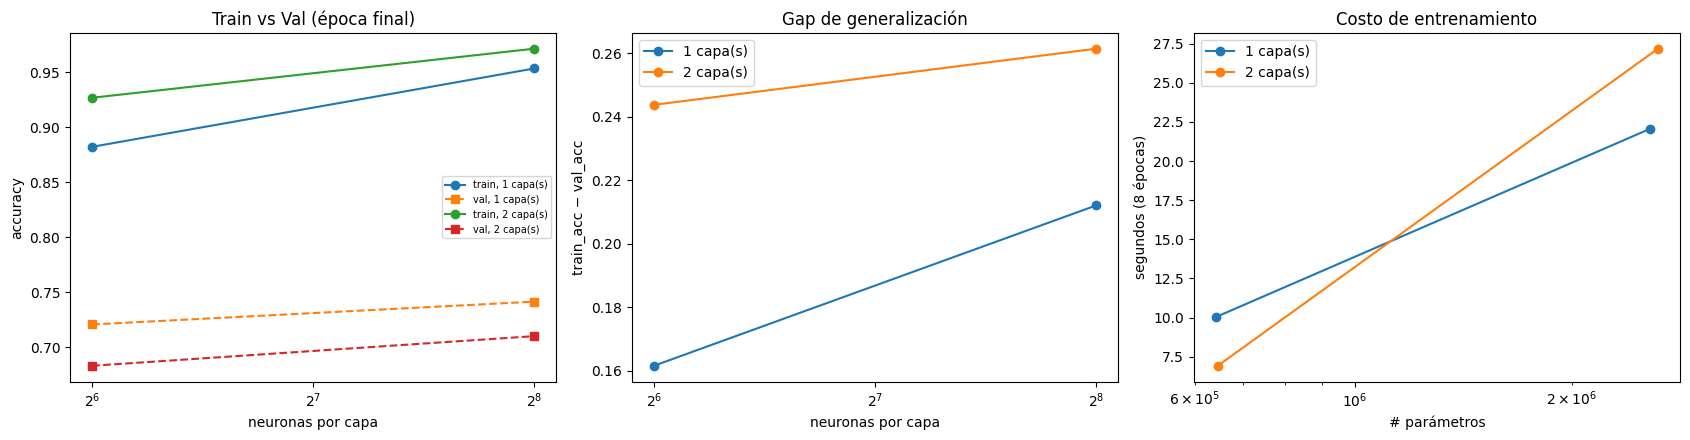

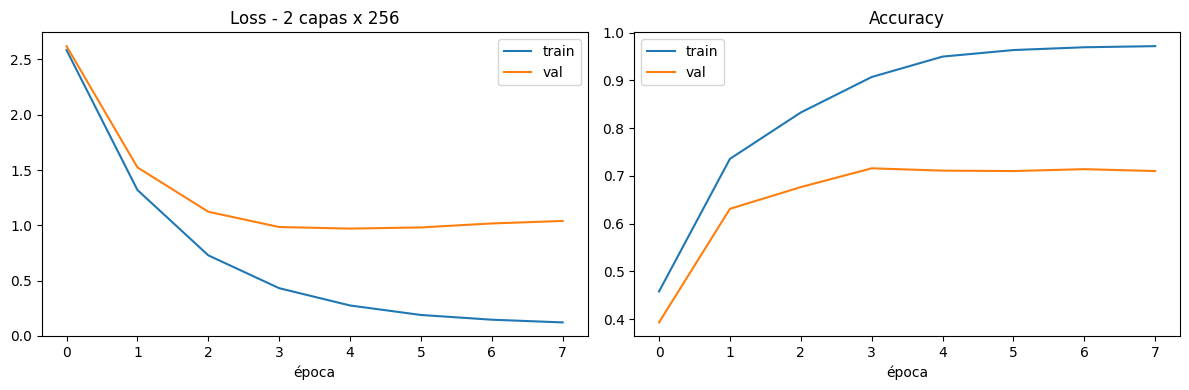

Configuración más sobreajustada: (2, 256) | train_acc = 0.972 | val_acc = 0.71


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for depth in OV_DEPTHS:
    d = df_ov[df_ov.layers == depth]
    axes[0].plot(d.units, d.train_acc, "o-", label=f"train, {depth} capa(s)")
    axes[0].plot(d.units, d.val_acc, "s--", label=f"val, {depth} capa(s)")
    axes[1].plot(d.units, d.gap, "o-", label=f"{depth} capa(s)")
    axes[2].plot(d.params, d.time_s, "o-", label=f"{depth} capa(s)")
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("neuronas por capa"); axes[0].set_ylabel("accuracy"); axes[0].set_title("Train vs Val (época final)"); axes[0].legend(fontsize=7)
axes[1].set_xscale("log", base=2); axes[1].set_xlabel("neuronas por capa"); axes[1].set_ylabel("train_acc − val_acc"); axes[1].set_title("Gap de generalización"); axes[1].legend()
axes[2].set_xscale("log"); axes[2].set_xlabel("# parámetros"); axes[2].set_ylabel("segundos (%d épocas)" % OV_EPOCHS); axes[2].set_title("Costo de entrenamiento"); axes[2].legend()
plt.tight_layout(); plt.show()

# Curvas de la configuración con mayor gap
worst = df_ov.sort_values("gap", ascending=False).iloc[0]
key = (int(worst.layers), int(worst.units))
h = ov_hist[key]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title(f"Loss - {key[0]} capas x {key[1]}"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(h["train_acc"], label="train"); ax[1].plot(h["val_acc"], label="val"); ax[1].set_title("Accuracy"); ax[1].set_xlabel("época"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Configuración más sobreajustada:", key, "| train_acc =", round(worst.train_acc, 3), "| val_acc =", round(worst.val_acc, 3))

In [ ]:
# Criterio de sobreajuste (ver 4.1): train_acc >= 0.95 y val_loss final > mínima + 0.05
cand = df_ov[(df_ov.train_acc >= 0.95) & (df_ov.val_loss_rise > 0.05)].sort_values("val_loss_rise", ascending=False)
print("Configuraciones que cumplen el criterio de overfitting (ordenadas por suba de val_loss):")
display(cand[["layers", "units", "params", "train_acc", "val_acc", "gap", "val_loss_min", "val_loss_final", "val_loss_rise", "time_s"]])
if len(cand):
    base = cand.iloc[0]
    motivo = "cumple el criterio y es la de mayor suba de val_loss (la más claramente sobreajustada)"
else:
    base = df_ov.sort_values("gap", ascending=False).iloc[0]
    motivo = "ninguna cumple el criterio; se usa la de mayor gap train-val"
OV_BASE_LAYERS, OV_BASE_UNITS = int(base.layers), int(base.units)
print(f"\n>>> Red sobreajustada elegida: {OV_BASE_LAYERS} capa(s) x {OV_BASE_UNITS} neuronas | train_acc={base.train_acc:.3f}, "
      f"val_acc={base.val_acc:.3f} | val_loss {base.val_loss_min:.3f} (mínima) -> {base.val_loss_final:.3f} (final). Motivo: {motivo}.")
del X_tr_ov, X_val_ov
if device.type == "cuda": torch.cuda.empty_cache()


Configuraciones que cumplen el criterio de overfitting (ordenadas por suba de val_loss):


,layers,units,params,train_acc,val_acc,gap,val_loss_min,val_loss_final,val_loss_rise,time_s
3,2,256,2631188,0.971605,0.710119,0.261486,0.970747,1.039658,0.06891,27.181489



>>> Red sobreajustada elegida: 2 capa(s) x 256 neuronas | train_acc=0.972, val_acc=0.710 | val_loss 0.971 (mínima) -> 1.040 (final). Motivo: cumple el criterio y es la de mayor suba de val_loss (la más claramente sobreajustada).


### 4.1 Criterio de "red sobreajustada" y elección de la red base

**Qué pasó con el criterio original.** El criterio inicial era `train_acc ≥ 0.99`. En este dataset la accuracy de entrenamiento se estanca por debajo de 0.99 aunque la red sea grande (en la corrida anterior ninguna configuración lo cumplió y la tabla salió vacía). Por eso lo ajustamos y lo queda explícito:

1. **`train_acc ≥ 0.95`**: la red ya memoriza casi todo el set de entrenamiento.
2. **`val_loss` final > `val_loss` mínima + 0.05**: la loss de validación empieza a *empeorar* mientras la de entrenamiento sigue bajando. Es la señal clásica de sobreajuste y es más confiable que el gap de accuracy, porque la accuracy de validación puede mantenerse mientras la red se vuelve cada vez más "sobreconfiada" y su loss sube.
3. Entre las que cumplen, se elige la de **mayor suba de `val_loss`** (la más claramente sobreajustada), que va a ser la red sobre la que se probó la regularización en la sección 5. Si ninguna cumple, se usa la de mayor gap `train_acc − val_acc`.

Lo que se lee en el gráfico de curvas: la `train_loss` sigue bajando todas las épocas, mientras la `val_loss` toca un mínimo en las primeras épocas y después sube. Eso quiere decir que a partir de ese punto la red deja de aprender patrones generales y empieza a memorizar documentos de entrenamiento. Cuanto más grande la red (más parámetros), antes aparece y más pronunciado es el efecto.

## 5. Regularización: L1 / L2 / L1+L2, Dropout y Batch Normalization

En la sección 4 se consiguieron modelos que sobreajustan. Ahora tomamos una de esas configuraciones y, con **todo lo demás fijo** (mismos datos, misma semilla, Adam, mismas épocas; versión rápida), activamos **de a una técnica por vez**. La búsqueda de Optuna (sección 3) mezcla muchas cosas a la vez; acá aislamos el efecto de cada técnica para poder explicarlo.

**Qué miramos en cada caso:**

| Qué miro | Para qué |
|---|---|
| Curvas de aprendizaje train / val | ¿La `val_loss` deja de subir? ¿En qué época está su mínimo? ¿Se achica el gap o aparece *underfitting*? |
| **Valores absolutos de los pesos** (media, máximo, fracción ≈ 0, entradas muertas) | L2 achica todos los pesos; L1 apaga los inútiles; dropout y BN actúan de forma indirecta |
| **Tiempos de entrenamiento** | Segundos por época **y** segundos hasta alcanzar el mejor `val_acc` (no son lo mismo) |
| **Learning rate** | Cada técnica cambia el rango útil de lr (sobre todo BatchNorm) |
| **Ruido en las curvas** | Oscilación de la curva entre épocas y dispersión de la loss entre mini-batches |



In [ ]:
# ---------- Configuración base: la red sobreajustada elegida en la sección 4.1 (ReLU, Adam) ----------
REG_LAYERS, REG_UNITS = OV_BASE_LAYERS, OV_BASE_UNITS   # la red sobreajustada elegida en 4.1
REG_EPOCHS, REG_BATCH, REG_LR = 8, 256, 1e-3
LR_EPOCHS = 5          # para el barrido de learning rate (5.5)

X_tr_sp, X_val_sp = get_vectorized(OV_PREP["rm_sw"], OV_PREP["norm"], OV_PREP["ngram"],
                                   OV_PREP["max_features"], OV_PREP["min_df"])
X_tr_r, X_val_r = to_dense(X_tr_sp), to_dense(X_val_sp)
yt_r = torch.tensor(y_tr, dtype=torch.long, device=device)
yv_r = torch.tensor(y_val, dtype=torch.long, device=device)


def run_variant(name, store, dropout=0.0, batchnorm=False, l1=0.0, l2=0.0, lr=REG_LR,
                epochs=REG_EPOCHS, batch=REG_BATCH):
    """Entrena la config base con UNA variante de regularización y guarda curvas + métricas en `store`."""
    set_seed()
    model = MLP(X_tr_r.shape[1], [REG_UNITS] * REG_LAYERS, NUM_CLASSES, "relu", dropout, batchnorm)
    opt = build_optimizer(param_groups(model, l2), "adam", lr)
    hist, t_train = train_model(model, opt, X_tr_r, yt_r, X_val_r, yv_r, epochs, batch,
                                tag=name, l1=l1, track_weights=True)
    vl = np.nan_to_num(np.array(hist["val_loss"]), nan=1e9, posinf=1e9)
    va = np.nan_to_num(np.array(hist["val_acc"]), nan=0.0)
    be, ba = int(np.argmin(vl)), int(np.argmax(va))
    first_w = next(m for m in model.modules() if isinstance(m, nn.Linear)).weight.detach().abs().flatten()
    sample = first_w[torch.randint(0, first_w.numel(), (200_000,), device=first_w.device)].cpu().numpy()
    row = dict(
        variant=name, batchnorm=batchnorm, dropout=dropout, l1=l1, l2=l2, lr=lr,
        time_s=t_train, s_per_epoch=t_train / epochs,
        time_to_best_acc=float(np.sum(hist["epoch_time"][:ba + 1])),
        train_acc=hist["train_acc"][-1], val_acc=hist["val_acc"][-1], best_val_acc=float(va.max()),
        best_epoch_acc=ba + 1, gap=hist["train_acc"][-1] - hist["val_acc"][-1],
        val_loss_min=float(vl[be]), epoch_min_val_loss=be + 1, val_loss_final=hist["val_loss"][-1],
        val_loss_rise=hist["val_loss"][-1] - float(vl[be]),
        train_loss_eval=hist["train_loss"][-1], train_loss_running=hist["train_loss_running"][-1],
        batch_loss_std=float(np.nanmean(hist["batch_loss_std"])),
        noise_val_acc=curve_noise(hist["val_acc"]), noise_val_loss=curve_noise(hist["val_loss"]),
        **weight_stats(model))
    store[name] = dict(hist=hist, row=row, w_sample=sample)
    print(f"{name:<22} train_acc={row['train_acc']:.3f} val_acc={row['val_acc']:.3f} "
          f"val_loss min@{row['epoch_min_val_loss']}={row['val_loss_min']:.3f} -> final={row['val_loss_final']:.3f} "
          f"| mean|w|={row['mean_abs_w']:.5f} | {t_train:.0f}s")


VARIANTS = {
    "baseline":            dict(),
    "L2 1e-4":             dict(l2=1e-4),
    "L2 1e-3":             dict(l2=1e-3),     # "exceso" de L2: debería producir underfitting
    "L1 1e-6":             dict(l1=1e-6),
    "L1 1e-5":             dict(l1=1e-5),
    "L1+L2 (1e-6, 1e-4)":  dict(l1=1e-6, l2=1e-4),
    "Dropout 0.5":         dict(dropout=0.5),
    "BN":                  dict(batchnorm=True),
    "BN + Dropout 0.2":    dict(batchnorm=True, dropout=0.2),
}

reg_results = {}
for name, kw in VARIANTS.items():
    if name not in reg_results:
        run_variant(name, reg_results, **kw)
df_reg = pd.DataFrame([v["row"] for v in reg_results.values()])

baseline               train_acc=0.972 val_acc=0.710 val_loss min@5=0.971 -> final=1.040 | mean|w|=0.03443 | 22s
L2 1e-4                train_acc=0.969 val_acc=0.689 val_loss min@6=1.034 -> final=1.084 | mean|w|=0.02284 | 40s
L2 1e-3                train_acc=0.900 val_acc=0.635 val_loss min@8=1.233 -> final=1.233 | mean|w|=0.01070 | 40s
L1 1e-6                train_acc=0.969 val_acc=0.699 val_loss min@6=1.027 -> final=1.084 | mean|w|=0.02634 | 24s
L1 1e-5                train_acc=0.925 val_acc=0.659 val_loss min@8=1.199 -> final=1.199 | mean|w|=0.01162 | 25s
L1+L2 (1e-6, 1e-4)     train_acc=0.967 val_acc=0.682 val_loss min@6=1.063 -> final=1.115 | mean|w|=0.02019 | 30s
Dropout 0.5            train_acc=0.947 val_acc=0.724 val_loss min@8=0.956 -> final=0.956 | mean|w|=0.02924 | 33s
BN                     train_acc=0.973 val_acc=0.716 val_loss min@3=0.994 -> final=1.046 | mean|w|=0.00880 | 24s
BN + Dropout 0.2       train_acc=0.973 val_acc=0.714 val_loss min@3=0.992 -> final=1.077 | mean|

### 5.2 Curvas de aprendizaje

,variant,train_acc,val_acc,best_val_acc,gap,val_loss_min,epoch_min_val_loss,val_loss_final,val_loss_rise,time_s
0,baseline,0.9716,0.7101,0.7159,0.2615,0.9707,5,1.0397,0.0689,22.4527
1,L2 1e-4,0.9690,0.6889,0.7000,0.2800,1.0338,6,1.0839,0.0501,39.6245
2,L2 1e-3,0.9003,0.6354,0.6412,0.2649,1.2330,8,1.2330,0.0000,39.8687
3,L1 1e-6,0.9691,0.6991,0.7008,0.2700,1.0271,6,1.0840,0.0570,24.4631
4,L1 1e-5,0.9250,0.6589,0.6589,0.2661,1.1994,8,1.1994,0.0000,24.6588
5,"L1+L2 (1e-6, 1e-4)",0.9670,0.6823,0.6938,0.2847,1.0632,6,1.1147,0.0515,30.3063
6,Dropout 0.5,0.9473,0.7243,0.7243,0.2230,0.9557,8,0.9557,0.0000,33.2925
7,BN,0.9734,0.7163,0.7221,0.2571,0.9941,3,1.0456,0.0515,23.9925
8,BN + Dropout 0.2,0.9733,0.7137,0.7238,0.2596,0.9917,3,1.0766,0.0849,22.6844


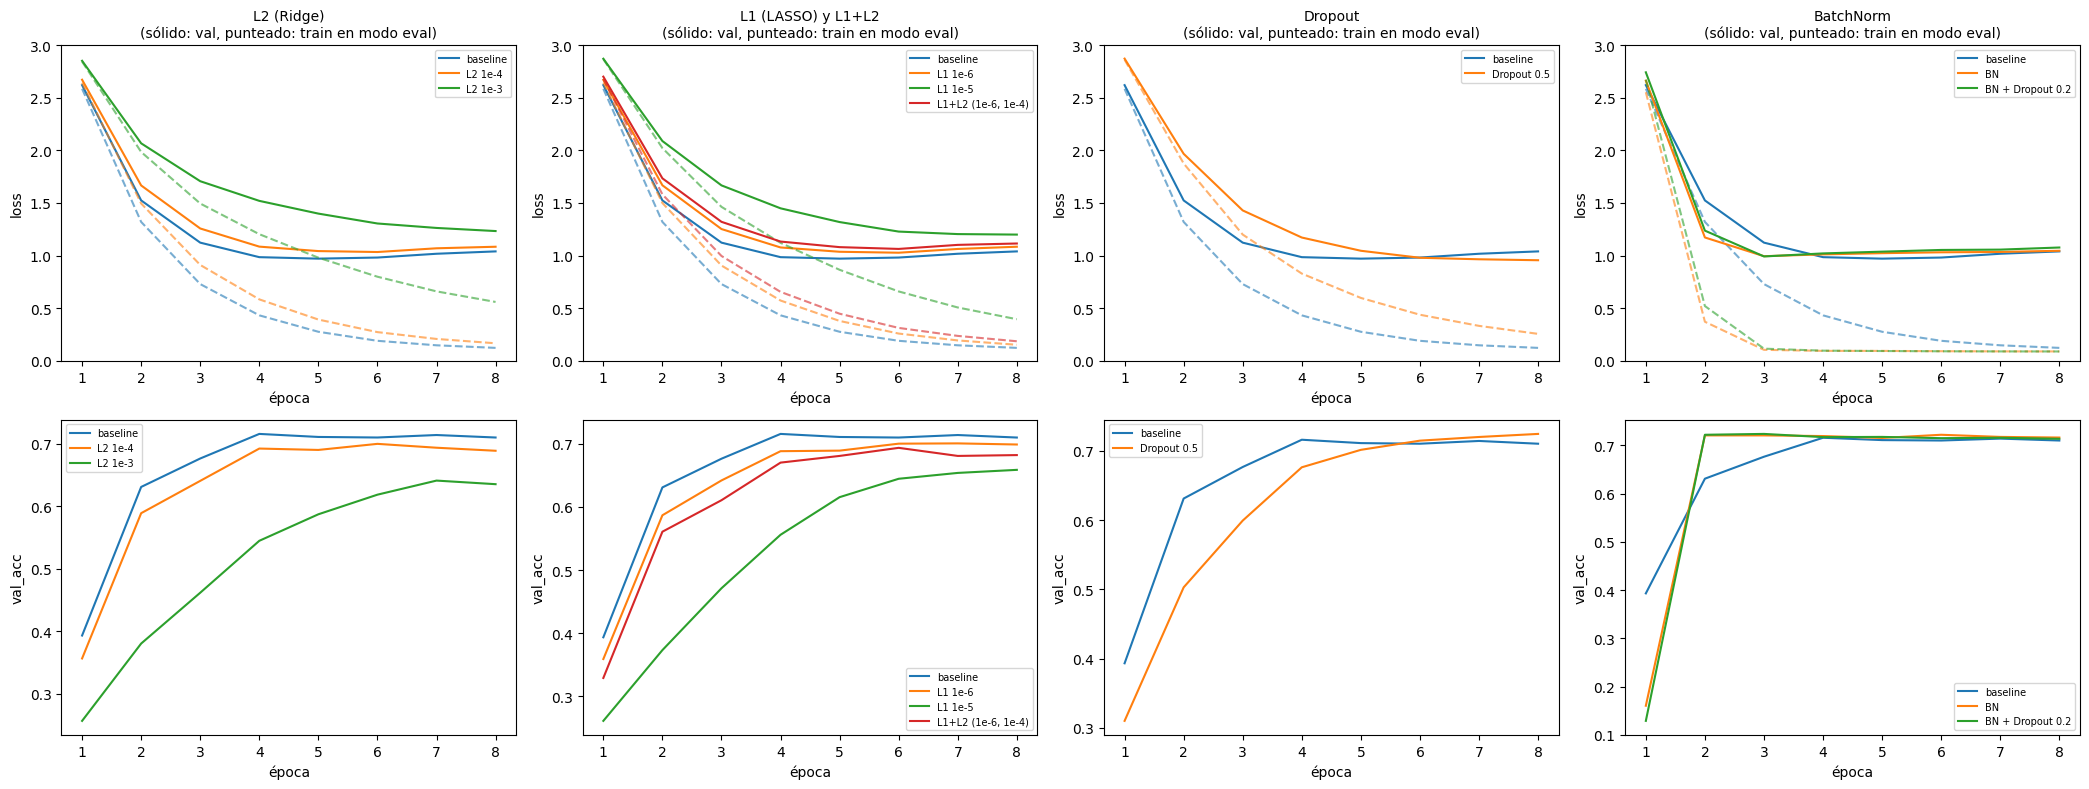

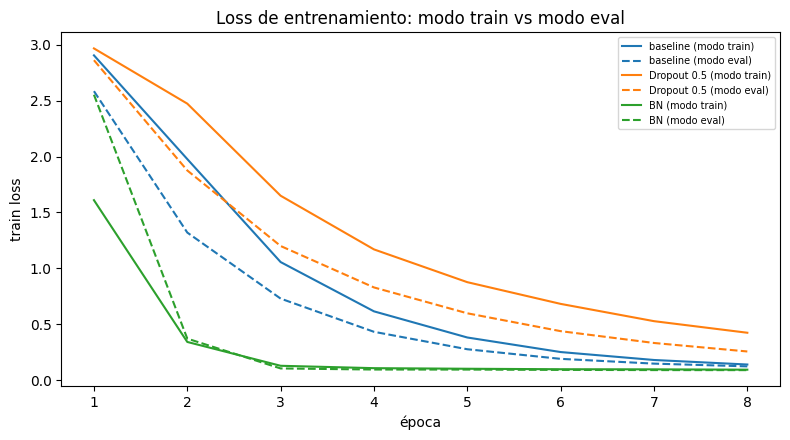

In [ ]:
cols_main = ["variant", "train_acc", "val_acc", "best_val_acc", "gap", "val_loss_min", "epoch_min_val_loss",
             "val_loss_final", "val_loss_rise", "time_s"]
display(df_reg[cols_main].round(4))

families = {
    "L2 (Ridge)":          ["baseline", "L2 1e-5", "L2 1e-4", "L2 1e-3"],
    "L1 (LASSO) y L1+L2":  ["baseline", "L1 1e-7", "L1 1e-6", "L1 1e-5", "L1+L2 (1e-6, 1e-4)"],
    "Dropout":             ["baseline", "Dropout 0.2", "Dropout 0.5"],
    "BatchNorm":           ["baseline", "BN", "BN + Dropout 0.2", "BN + L2 1e-4"],
}
fig, axes = plt.subplots(2, 4, figsize=(21, 8))
for ax_l, ax_a, (title, names) in zip(axes[0], axes[1], families.items()):
    for j, nm in enumerate([n for n in names if n in reg_results]):
        h = reg_results[nm]["hist"]; c = f"C{j}"
        ep = np.arange(1, len(h["val_loss"]) + 1)
        ax_l.plot(ep, h["val_loss"], color=c, label=nm)
        ax_l.plot(ep, h["train_loss"], color=c, ls="--", alpha=.6)
        ax_a.plot(ep, h["val_acc"], color=c, label=nm)
    ax_l.set_title(title + "\n(sólido: val, punteado: train en modo eval)", fontsize=10)
    ax_l.set_ylim(0, 3); ax_l.set_xlabel("época"); ax_l.set_ylabel("loss"); ax_l.legend(fontsize=7)
    ax_a.set_xlabel("época"); ax_a.set_ylabel("val_acc"); ax_a.legend(fontsize=7)
plt.tight_layout(); plt.show()

# Loss de entrenamiento en modo TRAIN (con dropout / BN activos) vs en modo EVAL
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, nm in enumerate([n for n in ["baseline", "Dropout 0.2", "Dropout 0.5", "BN"] if n in reg_results]):
    h = reg_results[nm]["hist"]; ep = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss_running"], color=f"C{j}", label=f"{nm} (modo train)")
    ax.plot(ep, h["train_loss"], color=f"C{j}", ls="--", label=f"{nm} (modo eval)")
ax.set_xlabel("época"); ax.set_ylabel("train loss"); ax.set_title("Loss de entrenamiento: modo train vs modo eval")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

### 5.3 Valores absolutos de los pesos

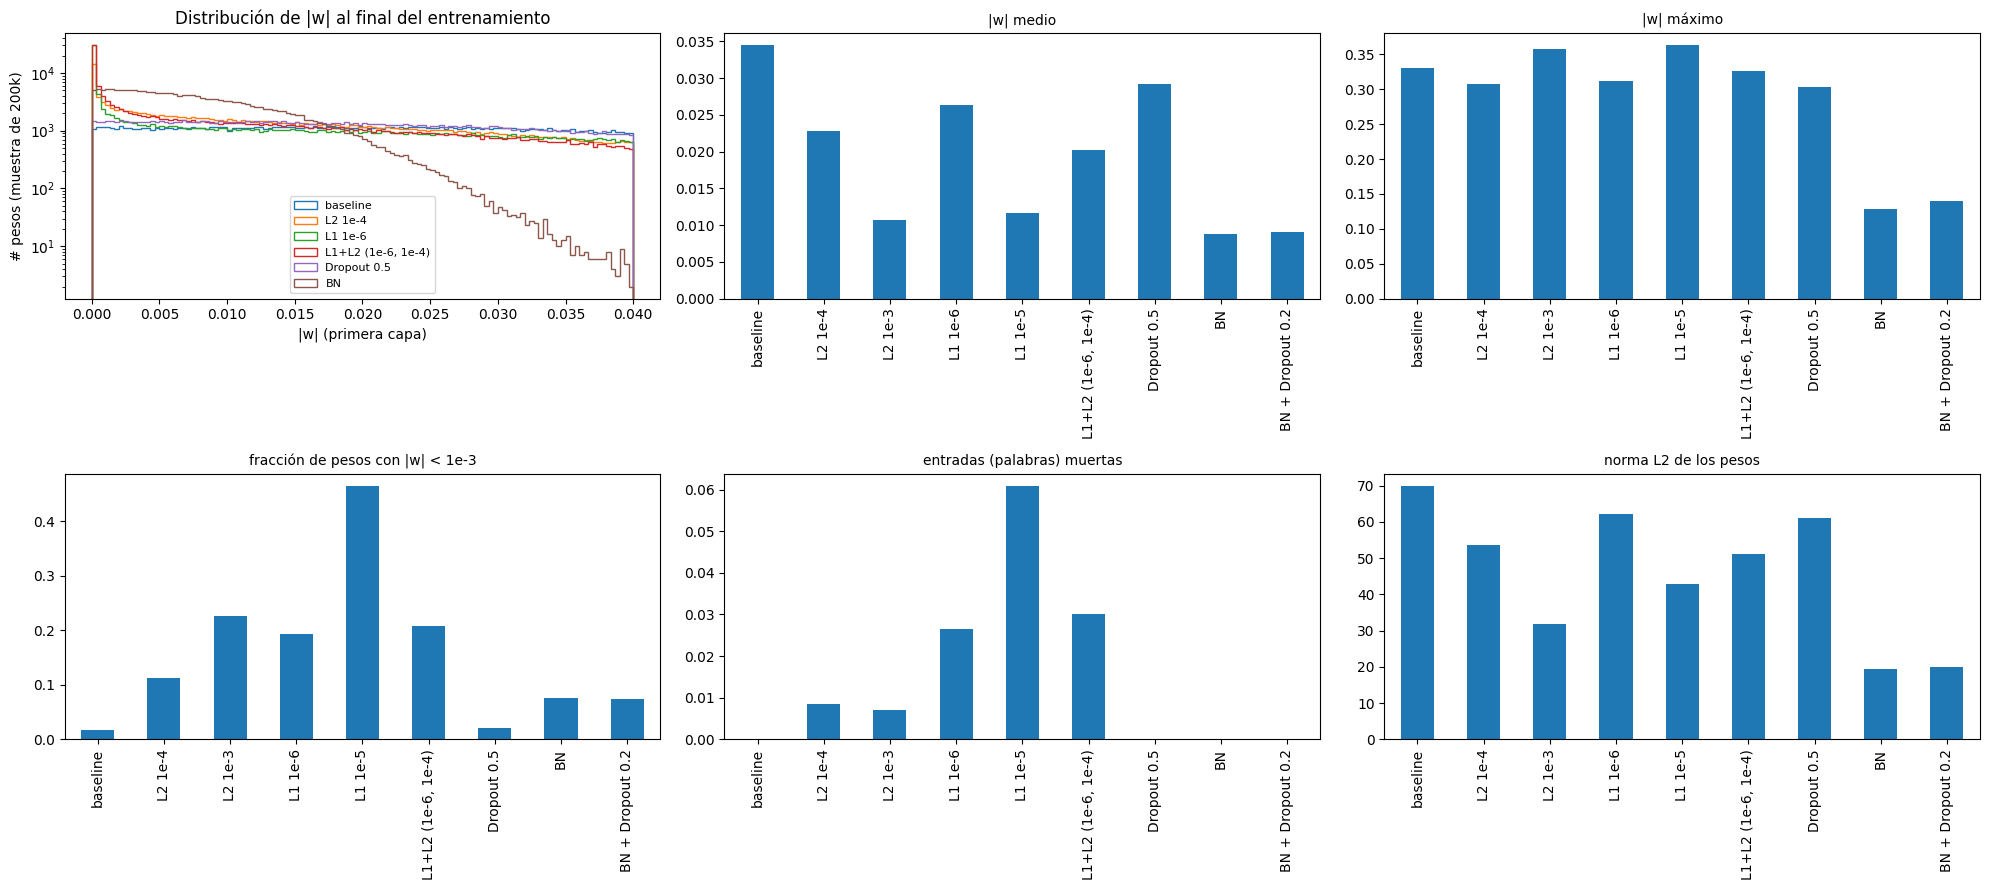

,variant,mean_abs_w,max_abs_w,frac_small_w,dead_inputs,w_norm
0,baseline,0.03443,0.33083,0.01647,0.0000,69.83121
1,L2 1e-4,0.02284,0.30762,0.11258,0.0086,53.73372
2,L2 1e-3,0.01070,0.35798,0.22621,0.0071,31.79290
3,L1 1e-6,0.02634,0.31190,0.19341,0.0265,62.07767
4,L1 1e-5,0.01162,0.36265,0.46408,0.0608,42.74502
5,"L1+L2 (1e-6, 1e-4)",0.02019,0.32561,0.20779,0.0302,51.26109
6,Dropout 0.5,0.02924,0.30387,0.02118,0.0000,61.09206
7,BN,0.00880,0.12780,0.07634,0.0000,19.38592
8,BN + Dropout 0.2,0.00909,0.13928,0.07390,0.0000,20.00198


In [ ]:
show = [n for n in ["baseline", "L2 1e-4", "L1 1e-6", "L1+L2 (1e-6, 1e-4)", "Dropout 0.5", "BN"] if n in reg_results]
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
ax = axes[0, 0]
for j, nm in enumerate(show):
    ax.hist(reg_results[nm]["w_sample"], bins=120, range=(0, 0.04), histtype="step", lw=1.6, label=nm, color=f"C{j}")
ax.set_yscale("log"); ax.set_xlabel("|w| (primera capa)"); ax.set_ylabel("# pesos (muestra de 200k)")
ax.set_title("Distribución de |w| al final del entrenamiento"); ax.legend(fontsize=8)

d = df_reg.set_index("variant")
for ax, col, ttl in zip([axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2]],
                        ["mean_abs_w", "max_abs_w", "frac_small_w", "dead_inputs", "w_norm"],
                        ["|w| medio", "|w| máximo", "fracción de pesos con |w| < 1e-3",
                         "entradas (palabras) muertas", "norma L2 de los pesos"]):
    d[col].plot.bar(ax=ax, color="C0"); ax.set_title(ttl, fontsize=10); ax.set_xlabel("")
plt.tight_layout(); plt.show()
display(df_reg[["variant", "mean_abs_w", "max_abs_w", "frac_small_w", "dead_inputs", "w_norm"]].round(5))

### 5.4 Tiempos de entrenamiento y ruido en las curvas

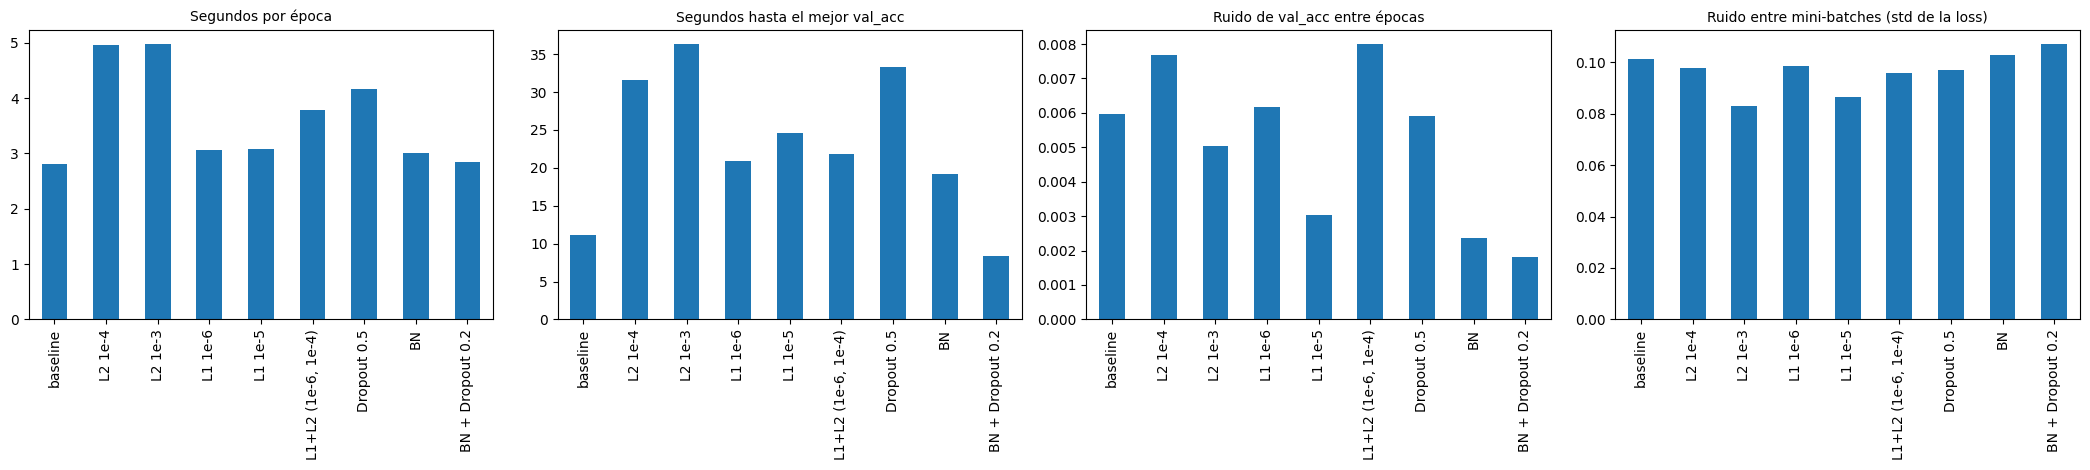

,variant,s_per_epoch,time_to_best_acc,best_epoch_acc,noise_val_acc,noise_val_loss,batch_loss_std,train_loss_running,train_loss_eval
0,baseline,2.8066,11.1813,4,0.0060,0.0334,0.1013,0.1392,0.1227
1,L2 1e-4,4.9531,31.5346,6,0.0077,0.0300,0.0979,0.1981,0.1664
2,L2 1e-3,4.9836,36.3873,7,0.0050,0.0189,0.0831,0.6804,0.5592
3,L1 1e-6,3.0579,20.9118,7,0.0062,0.0302,0.0985,0.1810,0.1523
4,L1 1e-5,3.0824,24.6588,8,0.0030,0.0214,0.0864,0.4937,0.3951
5,"L1+L2 (1e-6, 1e-4)",3.7883,21.7786,6,0.0080,0.0289,0.0959,0.2262,0.1856
6,Dropout 0.5,4.1616,33.2925,8,0.0059,0.0321,0.0968,0.4234,0.2559
7,BN,2.9991,19.1569,6,0.0024,0.0263,0.1030,0.0929,0.0889
8,BN + Dropout 0.2,2.8356,8.4214,3,0.0018,0.0370,0.1072,0.0979,0.0886


In [ ]:
d = df_reg.set_index("variant")
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
for ax, col, ttl in zip(axes, ["s_per_epoch", "time_to_best_acc", "noise_val_acc", "batch_loss_std"],
                        ["Segundos por época", "Segundos hasta el mejor val_acc",
                         "Ruido de val_acc entre épocas", "Ruido entre mini-batches (std de la loss)"]):
    d[col].plot.bar(ax=ax, color="C0"); ax.set_title(ttl, fontsize=10); ax.set_xlabel("")
plt.tight_layout(); plt.show()
display(df_reg[["variant", "s_per_epoch", "time_to_best_acc", "best_epoch_acc", "noise_val_acc",
                "noise_val_loss", "batch_loss_std", "train_loss_running", "train_loss_eval"]].round(4))

### 5.5 Learning rate con y sin Batch Normalization

Mismo modelo, mismos datos, `lr` ∈ {1e-3, 5e-2}, con y sin BatchNorm (5 épocas).

sin BN | lr=0.001      train_acc=0.950 val_acc=0.711 val_loss min@5=0.971 -> final=0.971 | mean|w|=0.03057 | 18s
sin BN | lr=0.05       train_acc=0.969 val_acc=0.642 val_loss min@1=1.215 -> final=2.089 | mean|w|=0.20749 | 16s
BN | lr=0.001          train_acc=0.973 val_acc=0.715 val_loss min@3=0.994 -> final=1.023 | mean|w|=0.00867 | 14s
BN | lr=0.05           train_acc=0.973 val_acc=0.669 val_loss min@1=1.087 -> final=1.635 | mean|w|=0.30472 | 13s


,variant,best_val_acc,best_epoch_acc,val_loss_min,val_loss_final,noise_val_acc,batch_loss_std,mean_abs_w,max_abs_w,s_per_epoch
0,sin BN | lr=0.001,0.7159,4,0.9707,0.9707,0.0063,0.1398,0.0306,0.2524,3.6090
1,sin BN | lr=0.05,0.6650,4,1.2148,2.0886,0.0117,0.2078,0.2075,2.8520,3.2458
2,BN | lr=0.001,0.7207,2,0.9941,1.0228,0.0002,0.1465,0.0087,0.1208,2.8356
3,BN | lr=0.05,0.6823,2,1.0865,1.6352,0.0006,0.1967,0.3047,2.4627,2.6066


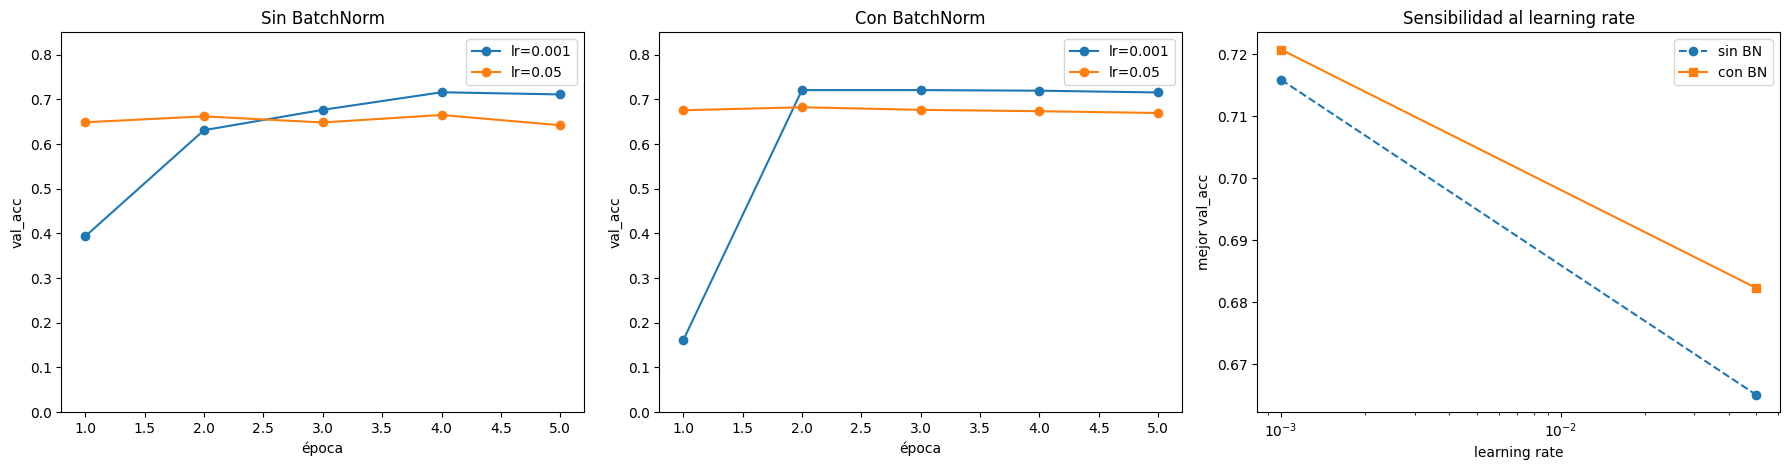

In [ ]:
LR_GRID = [1e-3, 5e-2]
lr_results = {}
for bn in [False, True]:
    for lr in LR_GRID:
        nm = f"{'BN' if bn else 'sin BN'} | lr={lr:g}"
        if nm not in lr_results:
            run_variant(nm, lr_results, batchnorm=bn, lr=lr, epochs=LR_EPOCHS)
df_lr = pd.DataFrame([v["row"] for v in lr_results.values()])
display(df_lr[["variant", "best_val_acc", "best_epoch_acc", "val_loss_min", "val_loss_final", "noise_val_acc",
               "batch_loss_std", "mean_abs_w", "max_abs_w", "s_per_epoch"]].round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, bn in zip(axes[:2], [False, True]):
    for lr in LR_GRID:
        h = lr_results[f"{'BN' if bn else 'sin BN'} | lr={lr:g}"]["hist"]
        ax.plot(range(1, LR_EPOCHS + 1), h["val_acc"], marker="o", label=f"lr={lr:g}")
    ax.set_title("Con BatchNorm" if bn else "Sin BatchNorm"); ax.set_xlabel("época"); ax.set_ylabel("val_acc")
    ax.set_ylim(0, 0.85); ax.legend()
for bn, mk in [(False, "o--"), (True, "s-")]:
    ys = [lr_results[f"{'BN' if bn else 'sin BN'} | lr={lr:g}"]["row"]["best_val_acc"] for lr in LR_GRID]
    axes[2].plot(LR_GRID, ys, mk, label="con BN" if bn else "sin BN")
axes[2].set_xscale("log"); axes[2].set_xlabel("learning rate"); axes[2].set_ylabel("mejor val_acc")
axes[2].set_title("Sensibilidad al learning rate"); axes[2].legend()
plt.tight_layout(); plt.show()

### 5.6 Diagnóstico automático con los números de esta corrida

Esta celda traduce las tablas anteriores a frases, para contrastarlas con lo que se explica en las cajas de texto de la sección 5.7.

In [ ]:
def _g(name, col):
    return float(df_reg.set_index("variant").loc[name, col])

def _chg(a, b):
    return f"{a:.4g} → {b:.4g} ({100 * (b - a) / a:+.0f}%)" if a else f"{a:.4g} → {b:.4g}"

def _best(prefix, exact=False):
    sub = df_reg[df_reg.variant == prefix] if exact else df_reg[df_reg.variant.str.startswith(prefix)]
    return None if sub.empty else sub.sort_values("val_loss_min").iloc[0]["variant"]

b = "baseline"
print("=== Diagnóstico automático ===\n")
print(f"• BASELINE (sin regularizar): val_loss mínima {_g(b,'val_loss_min'):.3f} en la época {int(_g(b,'epoch_min_val_loss'))} "
      f"y termina en {_g(b,'val_loss_final'):.3f} (sube {_g(b,'val_loss_rise'):.3f}). "
      f"train_acc {_g(b,'train_acc'):.3f} vs val_acc {_g(b,'val_acc'):.3f}. "
      f"|w| medio {_g(b,'mean_abs_w'):.5f}, máximo {_g(b,'max_abs_w'):.3f}.")

n = _best("L2 ")
if n:
    print(f"\n• L2 (mejor por val_loss: '{n}'): subida de val_loss {_chg(_g(b,'val_loss_rise'), _g(n,'val_loss_rise'))}; "
          f"|w| medio {_chg(_g(b,'mean_abs_w'), _g(n,'mean_abs_w'))}; |w| máximo {_chg(_g(b,'max_abs_w'), _g(n,'max_abs_w'))}; "
          f"fracción |w|<1e-3 {_chg(_g(b,'frac_small_w'), _g(n,'frac_small_w'))}; gap {_chg(_g(b,'gap'), _g(n,'gap'))}.")
n = _best("L1 ")
if n:
    print(f"\n• L1 (mejor por val_loss: '{n}'): fracción |w|<1e-3 {_chg(_g(b,'frac_small_w'), _g(n,'frac_small_w'))}; "
          f"entradas muertas {_chg(_g(b,'dead_inputs'), _g(n,'dead_inputs'))}; |w| máximo {_chg(_g(b,'max_abs_w'), _g(n,'max_abs_w'))}; "
          f"ruido de val_acc {_chg(_g(b,'noise_val_acc'), _g(n,'noise_val_acc'))}; s/época {_chg(_g(b,'s_per_epoch'), _g(n,'s_per_epoch'))}.")
n = _best("Dropout ")
if n:
    print(f"\n• DROPOUT (mejor por val_loss: '{n}'): loss de train en modo train {_g(n,'train_loss_running'):.3f} vs modo eval {_g(n,'train_loss_eval'):.3f}; "
          f"subida de val_loss {_chg(_g(b,'val_loss_rise'), _g(n,'val_loss_rise'))}; mejor época de val_acc {int(_g(b,'best_epoch_acc'))} → {int(_g(n,'best_epoch_acc'))}; "
          f"ruido entre mini-batches {_chg(_g(b,'batch_loss_std'), _g(n,'batch_loss_std'))}; s/época {_chg(_g(b,'s_per_epoch'), _g(n,'s_per_epoch'))}.")
n = _best("BN", exact=True)
if n:
    print(f"\n• BATCHNORM: s/época {_chg(_g(b,'s_per_epoch'), _g(n,'s_per_epoch'))}; segundos hasta el mejor val_acc {_chg(_g(b,'time_to_best_acc'), _g(n,'time_to_best_acc'))}; "
          f"época del mínimo de val_loss {int(_g(b,'epoch_min_val_loss'))} → {int(_g(n,'epoch_min_val_loss'))}; "
          f"|w| medio {_chg(_g(b,'mean_abs_w'), _g(n,'mean_abs_w'))} (ojo: con BN el |w| pierde significado); "
          f"ruido de val_acc {_chg(_g(b,'noise_val_acc'), _g(n,'noise_val_acc'))}.")

if "df_lr" in globals():
    hi = max(LR_GRID)
    a, c = df_lr.set_index("variant").loc[f"sin BN | lr={hi:g}"], df_lr.set_index("variant").loc[f"BN | lr={hi:g}"]
    print(f"\n• LEARNING RATE alto (lr={hi:g}): mejor val_acc sin BN = {a.best_val_acc:.3f} vs con BN = {c.best_val_acc:.3f}.")

=== Diagnóstico automático ===

• BASELINE (sin regularizar): val_loss mínima 0.971 en la época 5 y termina en 1.040 (sube 0.069). train_acc 0.972 vs val_acc 0.710. |w| medio 0.03443, máximo 0.331.

• L2 (mejor por val_loss: 'L2 1e-4'): subida de val_loss 0.06891 → 0.0501 (-27%); |w| medio 0.03443 → 0.02284 (-34%); |w| máximo 0.3308 → 0.3076 (-7%); fracción |w|<1e-3 0.01647 → 0.1126 (+584%); gap 0.2615 → 0.28 (+7%).

• L1 (mejor por val_loss: 'L1 1e-6'): fracción |w|<1e-3 0.01647 → 0.1934 (+1075%); entradas muertas 0 → 0.0265; |w| máximo 0.3308 → 0.3119 (-6%); ruido de val_acc 0.00597 → 0.006183 (+4%); s/época 2.807 → 3.058 (+9%).

• DROPOUT (mejor por val_loss: 'Dropout 0.5'): loss de train en modo train 0.423 vs modo eval 0.256; subida de val_loss 0.06891 → 0 (-100%); mejor época de val_acc 4 → 8; ruido entre mini-batches 0.1013 → 0.09685 (-4%); s/época 2.807 → 4.162 (+48%).

• BATCHNORM: s/época 2.807 → 2.999 (+7%); segundos hasta el mejor val_acc 11.18 → 19.16 (+71%); época del mín

### 5.7 Justificación de lo observado



>L2 (Ridge), L1 (LASSO) y L1+L2: ¿por qué se ven así los pesos y las curvas?


La red del TP sobreajusta: train_acc llega a ≈ 0.97 y se queda ahí, pero la val_loss toca su mínimo en las primeras épocas y después sube. Con ~10.000 entradas TF-IDF y ~9.000 documentos de entrenamiento, la red puede memorizar los textos apoyándose en palabras rarísimas, es decir, con pesos grandes sobre palabras que no generalizan, y la regularización ataca justamente eso.

L2 (Ridge) suma λ·Σw², y su gradiente tira de cada peso hacia cero en proporción a su tamaño (weight decay). Por eso se espera que el |w| medio y sobre todo el máximo bajen al subir λ, sin que casi ningún peso llegue a cero exacto. En las curvas, la val_loss sube menos después de su mínimo y el gap entre train y validación se achica. Si λ es demasiado grande hay underfitting, con ambas curvas altas, por eso se barre λ en escala logarítmica.

L1 (LASSO) suma λ·Σ|w| y empuja cada peso hacia cero con una fuerza constante, sin importar su tamaño. Los pesos que la clasificación no defiende llegan a ≈ 0 y los útiles resisten. Se espera entonces que suba la fracción de pesos casi nulos y que aparezcan palabras “muertas” (todas sus conexiones ≈ 0), que es la idea de LASSO de seleccionar variables. A diferencia de L2, el |w| máximo no tiene por qué bajar. Con Adam y mini-batches los pesos oscilan alrededor de cero en lugar de clavarse en cero exacto, por eso se mide |w| < 1e-3. Esa oscilación vuelve más ruidosas las curvas, y un λ muy grande o un lr alto lo empeoran.

L1+L2 (elastic net) combina ambas: L1 apaga lo inútil y L2 reparte el peso entre palabras correlacionadas, así que se espera un |w| máximo más contenido y un comportamiento más estable que con L1 solo.

En tiempos, L2 casi no cambia el costo por época, y L1 es algo más lenta porque recorre todos los parámetros en cada paso. Ninguna acelera el entrenamiento, solo cambian cuánto se puede entrenar antes de sobreajustar. En learning rate, lo que importa es el producto lr·λ, y con Adam los λ útiles no coinciden con los de SGD puro porque el gradiente de la penalización se reescala igual que el de la loss.

Dropout

El dropout apaga al azar una fracción p de las neuronas en cada paso, así que ninguna puede apoyarse en que otra esté presente para corregirla (se evita la co-adaptación). La red aprende representaciones más redundantes y robustas, como si entrenara muchas sub-redes que comparten pesos y las promediara al evaluar. En eval() se usan todas las neuronas, y PyTorch ya reescala durante el entrenamiento, por lo que no hay que corregir nada a mano.

Esto es lo que se espera ver en los resultados:

Loss de entrenamiento: en modo train es más alta que en modo eval, y la diferencia crece con p. No es un error: en train la red está recortada por el dropout y en eval tiene todas sus neuronas.
Sobreajuste: el gap entre train y validación es menor y la val_loss sube menos, más con p = 0.5 que con 0.2. Memorizar un documento exige combinaciones muy específicas de neuronas, y el dropout las rompe todo el tiempo.
Ruido: las curvas son más ruidosas, porque cada mini-batch lo procesa una sub-red distinta. Ese ruido es parte del efecto regularizador.
Convergencia: es más lenta, y el mejor val_acc aparece en épocas más tardías. Por eso en la búsqueda de Optuna subimos las épocas de 8 a 10 y dimos más calentamiento al pruner, porque antes los trials con dropout quedaban podados antes de mostrar su ventaja.
Tiempos: el tiempo por época es casi igual, pero hace falta más tiempo hasta el mejor resultado.
Pesos: el dropout no penaliza su tamaño directamente, así que no se espera un |w| medio mucho menor que con L2. Lo habitual es que el |w| máximo baje algo, porque ningún peso individual se vuelve imprescindible.

El límite es que con p muy alto y capas angostas la red pierde capacidad y aparece underfitting, por eso las capas anchas toleran más dropout. Un dato de la primera búsqueda sin estas mejoras es coherente con esto: el mejor trial tenía una capa de 256 neuronas y p ≈ 0.29, un valor moderado.

Batch Normalization

La Batch Normalization normaliza, antes de la activación, cada neurona con la media y el desvío del mini-batch y después deja que la red reescale con dos parámetros aprendidos (γ y β), de modo que cada capa recibe entradas de escala predecible sin importar lo que hizo la anterior. Gracias a eso tolera learning rates bastante más altos: sin BN, un lr alto agranda las actualizaciones y las activaciones se vuelven enormes o diminutas, así que el entrenamiento diverge o se estanca, mientras que con BN la escala se renormaliza en cada paso. Eso debería verse en la sección 5.5, donde el modelo sin BN se degrada al pasar de 1e-3 a 5e-2 y el modelo con BN sigue aprendiendo, aunque con un lr extremo también aparece ruido. En tiempos hay que mirar dos números: cada época con BN cuesta más, pero como acepta un lr mayor y converge en menos épocas, el tiempo hasta el mejor val_acc puede ser menor. También reduce la sensibilidad a la inicialización de pesos, porque una mala escala inicial no se arrastra de capa en capa. Como las estadísticas se calculan con el mini-batch, la salida de cada documento depende un poco de los demás documentos del batch, lo que agrega ruido parecido a un dropout suave, con curvas más irregulares (sobre todo con batch chico) y un leve efecto regularizador. Además, en eval() BN usa promedios móviles que en las primeras épocas todavía no se estabilizaron, así que la val_loss puede dar saltos iniciales. Hay que tener cuidado al leer los pesos: la normalización cancela cualquier multiplicación de los pesos de la capa por una constante, por lo que el |w| absoluto pierde significado y no es comparable con el de una red sin BN, y por lo mismo L2 junto con BN actúa sobre todo controlando el learning rate efectivo y no simplificando la función. Por último, BN no es un regularizador fuerte: entrena más rápido y por eso llega antes al sobreajuste, así que se espera que la val_loss toque su mínimo en una época más temprana que el baseline, y lo natural es combinarlo con dropout o L2, o cortar con early stopping, aunque BN + dropout no siempre suman porque ambos agregan ruido y alteran la varianza entre train y eval.

### 5.8 Optimizadores y momentos: experimento controlado con réplicas

La búsqueda de Optuna mezcla muchos hiperparámetros a la vez, y con una sola corrida por configuración no se puede saber si una diferencia pequeña es real o es ruido de la semilla. Acá se compara **un hiperparámetro por vez** con **3 semillas** por configuración (misma red de 1 capa × 256, mismos datos, mismas épocas):

| Configuración | lr | Qué compara |
|---|---|---|
| SGD, momentum 0 | 1.0 | Línea base de SGD |
| SGD, momentum 0.9 | 0.1 | Efecto del **momento de 1er orden** (mismo lr efectivo: lr / (1 − m) = 1.0) |
| RMSprop, α = 0.99 | 1e-3 | **Momento de 2do orden** (media móvil del gradiente al cuadrado) |
| Adam, β1 = 0.9, β2 = 0.999 | 1e-3 | 1er + 2do orden |
| Adam, β1 = 0.5, β2 = 0.999 | 1e-3 | Efecto de **reducir el momento de 1er orden** respecto de la fila anterior |

El **desvío entre semillas** que se obtiene acá sirve de referencia en todo el TP: una diferencia de `val_acc` menor que ese desvío no se debe interpretar como mejora real.

,val_acc_final_media,val_acc_final_std,val_acc_max_media,mejor_epoca_media,ruido_medio,tiempo_s
config,,,,,,
SGD (momentum 0),0.3724,0.0295,0.3868,7.3333,0.0341,16.9675
SGD (momentum 0.9),0.4721,0.0033,0.4741,6.6667,0.0531,17.6300
RMSprop (alpha 0.99),0.7396,0.0034,0.7461,5.3333,0.0020,19.3839
"Adam (b1 0.9, b2 0.999)",0.7430,0.0018,0.7433,7.3333,0.0041,22.2635
"Adam (b1 0.5, b2 0.999)",0.7437,0.0020,0.7437,7.6667,0.0024,21.7580


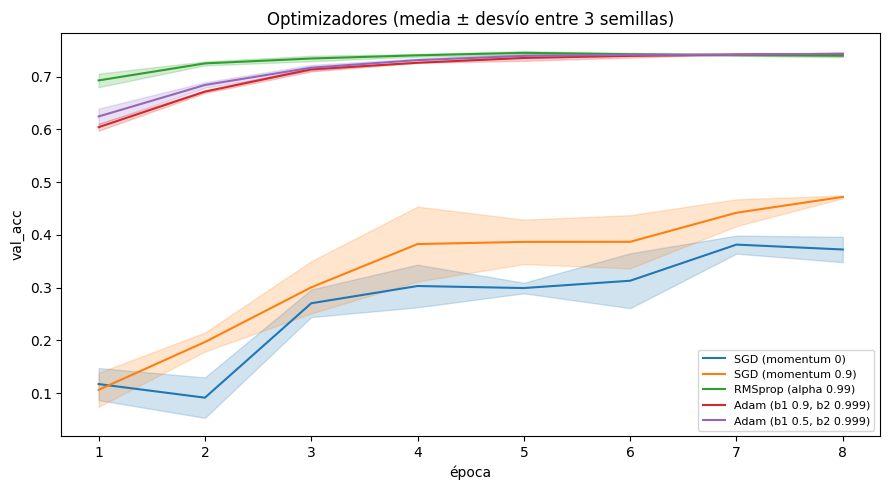

Desvío típico de val_acc entre semillas: 0.0080  (referencia: diferencias menores que esto no son concluyentes)


In [ ]:
OPT_SEEDS = [0, 1, 2]
OPT_EPOCHS = 8
OPT_UNITS = 256
OPT_CONFIGS = {
    "SGD (momentum 0)":        ("sgd", 1.0, dict(momentum=0.0)),
    "SGD (momentum 0.9)":      ("sgd", 0.1, dict(momentum=0.9)),
    "RMSprop (alpha 0.99)":    ("rmsprop", 1e-3, dict(alpha=0.99)),
    "Adam (b1 0.9, b2 0.999)": ("adam", 1e-3, dict(beta1=0.9, beta2=0.999)),
    "Adam (b1 0.5, b2 0.999)": ("adam", 1e-3, dict(beta1=0.5, beta2=0.999)),
}
opt_runs, opt_curves = [], {}
for name, (o, lr_o, kw) in OPT_CONFIGS.items():
    for sd in OPT_SEEDS:
        set_seed(sd)
        m = MLP(X_tr_r.shape[1], [OPT_UNITS], NUM_CLASSES, "relu")
        opt = build_optimizer(m.parameters(), o, lr_o, **kw)
        h, t = train_model(m, opt, X_tr_r, yt_r, X_val_r, yv_r, OPT_EPOCHS, 256, tag=name, eval_train=False)
        opt_curves.setdefault(name, []).append(h["val_acc"])
        opt_runs.append(dict(config=name, seed=sd, final_val_acc=h["val_acc"][-1], best_val_acc=max(h["val_acc"]),
                             best_epoch=int(np.argmax(h["val_acc"])) + 1, val_loss_min=min(h["val_loss"]), time_s=t,
                             noise_val_acc=curve_noise(h["val_acc"], skip=1)))
df_opt = pd.DataFrame(opt_runs)
summ = df_opt.groupby("config", sort=False).agg(
    val_acc_final_media=("final_val_acc", "mean"), val_acc_final_std=("final_val_acc", "std"),
    val_acc_max_media=("best_val_acc", "mean"), mejor_epoca_media=("best_epoch", "mean"),
    ruido_medio=("noise_val_acc", "mean"), tiempo_s=("time_s", "mean")).round(4)
display(summ)

fig, ax = plt.subplots(figsize=(9, 5))
for j, (name, curves) in enumerate(opt_curves.items()):
    arr = np.array(curves); mu, sd_ = arr.mean(0), arr.std(0); ep = np.arange(1, arr.shape[1] + 1)
    ax.plot(ep, mu, color=f"C{j}", label=name); ax.fill_between(ep, mu - sd_, mu + sd_, color=f"C{j}", alpha=.2)
ax.set_xlabel("época"); ax.set_ylabel("val_acc"); ax.set_title("Optimizadores (media ± desvío entre 3 semillas)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
SEED_STD = float(df_opt.groupby("config")["final_val_acc"].std().mean())
print(f"Desvío típico de val_acc entre semillas: {SEED_STD:.4f}  (referencia: diferencias menores que esto no son concluyentes)")

Optimizadores

Las entradas del TP son vectores TF-IDF muy ralos, donde cada palabra aparece en pocos documentos, y eso explica por qué SGD queda atrás: como mueve cada peso en proporción a su gradiente, las palabras raras reciben gradientes diminutos y esporádicos y avanzan muy despacio, por lo que necesita learning rates grandes (en la búsqueda llega a 20) y más épocas para alcanzar a los otros. RMSprop y Adam, en cambio, dividen cada paso por una media móvil del gradiente al cuadrado (el momento de 2do orden), lo que equivale a darle a cada peso su propio learning rate y hace que las palabras raras reciban pasos relativamente grandes, así que se espera que lleguen antes a un buen val_acc, con una curva que sube más rápido en las primeras épocas. El momento de 1er orden (momentum en SGD, β1 en Adam) promedia los gradientes recientes, suaviza el zigzag y acelera cuando el gradiente apunta siempre para el mismo lado; para aislar su efecto se compara SGD con m = 0 y m = 0.9 manteniendo el mismo lr efectivo, y se espera una curva más suave o más rápida con m = 0.9, mientras que bajar β1 a 0.5 en Adam le da menos memoria, así que reacciona más rápido a cada batch pero es más ruidoso. Solo se consideran reales las diferencias que superan el desvío entre semillas: si dos optimizadores quedan dentro de ese desvío, la conclusión honesta es que en este problema y con este presupuesto son equivalentes, no que uno sea mejor. Esa precaución es justamente lo que faltaba en la búsqueda anterior, que tenía una sola corrida por configuración y 36 de 40 trials en el mismo optimizador.

## 6. Análisis transversal de todos los entrenamientos

Juntamos todos los trials en un DataFrame (completados + podados) y comparamos performance, tiempos y regularización.

In [ ]:
df = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs"))
df.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in df.columns]
df["state"] = df["state"].astype(str).str.replace("TrialState.", "", regex=False)
df["n_layers"] = df["n_layers"].astype(int)
df["arch"] = df.apply(lambda r: "-".join(str(int(r[f"units_l{i+1}"])) for i in range(r["n_layers"])), axis=1)

# Regularización: los hiperparámetros condicionales quedan NaN cuando no se muestrean -> significa "no se usó"
for c in ["l1", "l2", "dropout"]:
    if c not in df: df[c] = 0.0
    df[c] = df[c].fillna(0.0)
df["batchnorm"] = df["batchnorm"].astype(bool)
df["use_dropout"] = df["dropout"] > 0
# Ruido de la curva val_acc por época (solo trials con >= 5 épocas reportadas)
noise_by_trial = {t.number: curve_noise([v for _, v in sorted(t.intermediate_values.items())])
                  for t in study.trials}
df["val_acc_noise"] = df["number"].map(noise_by_trial)

done = df[df.state == "COMPLETE"].copy()
done["gap"] = done["train_acc"] - done["value"]
print(df.state.value_counts().to_string())
print(f"\nTrials: {len(df)} | completos: {len(done)} | podados: {(df.state=='PRUNED').sum()}")

cols = ["number", "value", "train_acc", "gap", "optimizer", "activation", "n_layers", "arch", "batchnorm",
        "reg_type", "l1", "l2", "dropout", "batch_size", "n_params", "train_time", "best_epoch",
        "val_acc_noise", "mean_abs_w"]
print("\nTop 10 por val_acc:")
display(done.sort_values("value", ascending=False)[cols].head(10).round(5))


state
COMPLETE    16
PRUNED      10

Trials: 26 | completos: 16 | podados: 10

Top 10 por val_acc:


,number,value,train_acc,gap,optimizer,activation,n_layers,arch,batchnorm,reg_type,l1,l2,dropout,batch_size,n_params,train_time,best_epoch,val_acc_noise,mean_abs_w
23,23,0.72382,0.94630,0.22249,adam,silu,1,1024,False,l1,0.00000,0.0,0.53527,128,5141524,79.99590,6.0,0.00249,0.04290
14,14,0.71631,0.93271,0.21641,adam,leaky_relu,2,128-32,True,l1,0.00000,0.0,0.35299,512,1285076,14.20501,10.0,0.02868,0.01903
25,25,0.71321,0.95912,0.24591,rmsprop,silu,2,1024-1024,True,l1,0.00000,0.0,0.52123,128,6193172,95.36491,7.0,0.00233,0.00802
4,4,0.70570,0.97348,0.26778,rmsprop,leaky_relu,3,128-128-64,True,l1,0.00001,0.0,0.42598,512,1306516,18.41287,3.0,0.01420,0.02286
1,1,0.69465,0.97227,0.27762,rmsprop,silu,1,256,False,l1,0.00000,0.0,0.00000,128,1285396,22.36643,1.0,0.00455,0.14289
7,7,0.69289,0.97437,0.28148,rmsprop,leaky_relu,1,256,True,l1,0.00000,0.0,0.41293,512,1285652,12.16427,2.0,0.00259,0.02653
16,16,0.69200,0.97470,0.28270,rmsprop,leaky_relu,2,128-64,True,none,0.00000,0.0,0.00000,512,1289876,12.95120,5.0,0.02395,0.00870
15,15,0.69156,0.97205,0.28049,sgd,gelu,2,128-32,True,l1,0.00000,0.0,0.37030,512,1285076,13.17207,7.0,0.02841,0.00825
13,13,0.68714,0.97161,0.28446,rmsprop,silu,1,128,False,none,0.00000,0.0,0.00000,512,642708,5.65246,2.0,0.00277,0.19218
11,11,0.68316,0.96840,0.28524,adam,leaky_relu,1,256,False,l1,0.00000,0.0,0.00000,128,1285396,19.78103,1.0,0.00911,0.16595


### 6.1 Efecto del pruning en tiempo

Épocas ejecutadas: 205 de 260 posibles sin pruning (79%)
Tiempo real en trials: 11.5 min | ahorro estimado por pruning: ~3.1 min


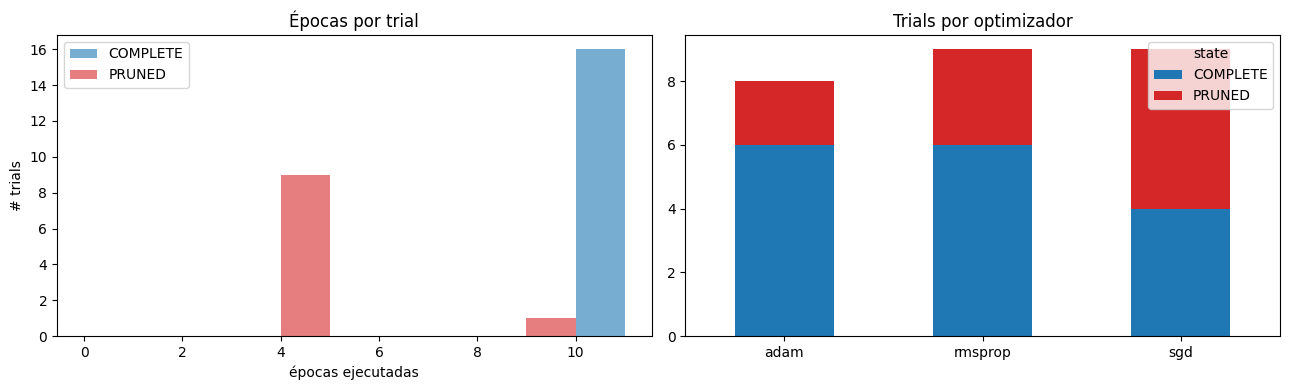

In [ ]:
pr = df[df.state == "PRUNED"]
epochs_used = df["epochs_run"].fillna(0)
epochs_if_no_prune = len(df) * MAX_EPOCHS_SEARCH
print(f"Épocas ejecutadas: {int(epochs_used.sum())} de {epochs_if_no_prune} posibles sin pruning "
      f"({100*epochs_used.sum()/epochs_if_no_prune:.0f}%)")

# Estimación del tiempo ahorrado: tiempo por época promedio * épocas evitadas
t_train_all = df["wall_time"].sum()
sec_per_epoch = t_train_all / max(epochs_used.sum(), 1)
saved = sec_per_epoch * (epochs_if_no_prune - epochs_used.sum())
print(f"Tiempo real en trials: {t_train_all/60:.1f} min | ahorro estimado por pruning: ~{saved/60:.1f} min")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for state, color in [("COMPLETE", "tab:blue"), ("PRUNED", "tab:red")]:
    d = df[df.state == state]
    ax[0].hist(d["epochs_run"], bins=range(0, MAX_EPOCHS_SEARCH + 2), alpha=.6, label=state, color=color)
ax[0].set_xlabel("épocas ejecutadas"); ax[0].set_ylabel("# trials"); ax[0].legend(); ax[0].set_title("Épocas por trial")
pd.crosstab(df.optimizer, df.state).plot.bar(stacked=True, ax=ax[1], color={"COMPLETE": "tab:blue", "PRUNED": "tab:red"}, rot=0)
ax[1].set_title("Trials por optimizador"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

### 6.2 Performance y tiempo por optimizador, activación y profundidad

In [ ]:
def summarize(by):
    g = done.groupby(by)
    out = pd.DataFrame({
        "trials_completos": g.size(),
        "val_acc_media": g["value"].mean(),
        "val_acc_max": g["value"].max(),
        "gap_medio": g["gap"].mean(),
        "tiempo_medio_s": g["train_time"].mean(),
        "params_medios": g["n_params"].mean(),
        "ruido_val_acc": g["val_acc_noise"].mean(),
        "mean_abs_w": g["mean_abs_w"].mean(),
    })
    tot = df.groupby(by).size().rename("trials_totales")
    pruned = df[df.state == "PRUNED"].groupby(by).size().rename("podados")
    return out.join(tot, how="outer").join(pruned, how="left").fillna({"podados": 0}).sort_values("val_acc_max", ascending=False).round(4)

for by in ["optimizer", "activation", "n_layers", "batchnorm", "reg_type", "use_dropout"]:
    print(f"\n=== por {by} ===")
    display(summarize(by))



=== por optimizer ===


,trials_completos,val_acc_media,val_acc_max,gap_medio,tiempo_medio_s,params_medios,ruido_val_acc,mean_abs_w,trials_totales,podados
optimizer,,,,,,,,,,
adam,6,0.6031,0.7238,0.1945,38.8415,2.280308e+06,0.0081,0.0439,8,2
rmsprop,6,0.6976,0.7132,0.2733,27.8187,2.000553e+06,0.0084,0.0669,9,3
sgd,4,0.5282,0.6916,0.1436,22.2889,1.910404e+06,0.0293,0.2467,9,5



=== por activation ===


,trials_completos,val_acc_media,val_acc_max,gap_medio,tiempo_medio_s,params_medios,ruido_val_acc,mean_abs_w,trials_totales,podados
activation,,,,,,,,,,
silu,4.0,0.7047,0.7238,0.2576,50.8449,3.315700e+06,0.0030,0.0965,5,1.0
leaky_relu,7.0,0.6466,0.7163,0.2349,28.2703,1.755915e+06,0.0117,0.0393,13,6.0
gelu,2.0,0.5791,0.6916,0.2032,9.2909,9.013640e+05,0.0149,0.0098,3,1.0
elu,3.0,0.4714,0.6558,0.1000,23.0876,1.989951e+06,0.0306,0.3235,3,0.0
relu,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1.0
tanh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1.0



=== por n_layers ===


,trials_completos,val_acc_media,val_acc_max,gap_medio,tiempo_medio_s,params_medios,ruido_val_acc,mean_abs_w,trials_totales,podados
n_layers,,,,,,,,,,
1,10,0.5735,0.7238,0.1777,32.4305,2125895.2,0.0117,0.1553,12,2
2,4,0.7033,0.7163,0.2564,33.9233,2513300.0,0.0208,0.0110,7,3
3,2,0.6843,0.7057,0.2892,14.5591,1007316.0,0.0076,0.0274,7,5


... (2 outputs left out)


=== por reg_type ===


,trials_completos,val_acc_media,val_acc_max,gap_medio,tiempo_medio_s,params_medios,ruido_val_acc,mean_abs_w,trials_totales,podados
reg_type,,,,,,,,,,
l1,11,0.6188,0.7238,0.2084,36.7009,2.311304e+06,0.0100,0.1278,19,8.0
none,3,0.6625,0.6920,0.2154,25.3376,2.354452e+06,0.0334,0.0699,3,0.0
l1_l2,1,0.6558,0.6558,0.3167,3.9847,3.214280e+05,0.0042,0.0240,3,2.0
l2,1,0.4666,0.4666,0.1259,5.4097,5.176520e+05,0.0013,0.0113,1,0.0



=== por use_dropout ===


,trials_completos,val_acc_media,val_acc_max,gap_medio,tiempo_medio_s,params_medios,ruido_val_acc,mean_abs_w,trials_totales,podados
use_dropout,,,,,,,,,,
True,9,0.6534,0.7238,0.2123,44.9313,3.008888e+06,0.0177,0.0179,16,7
False,7,0.5766,0.6947,0.2101,12.1050,8.923994e+05,0.0081,0.2129,10,3


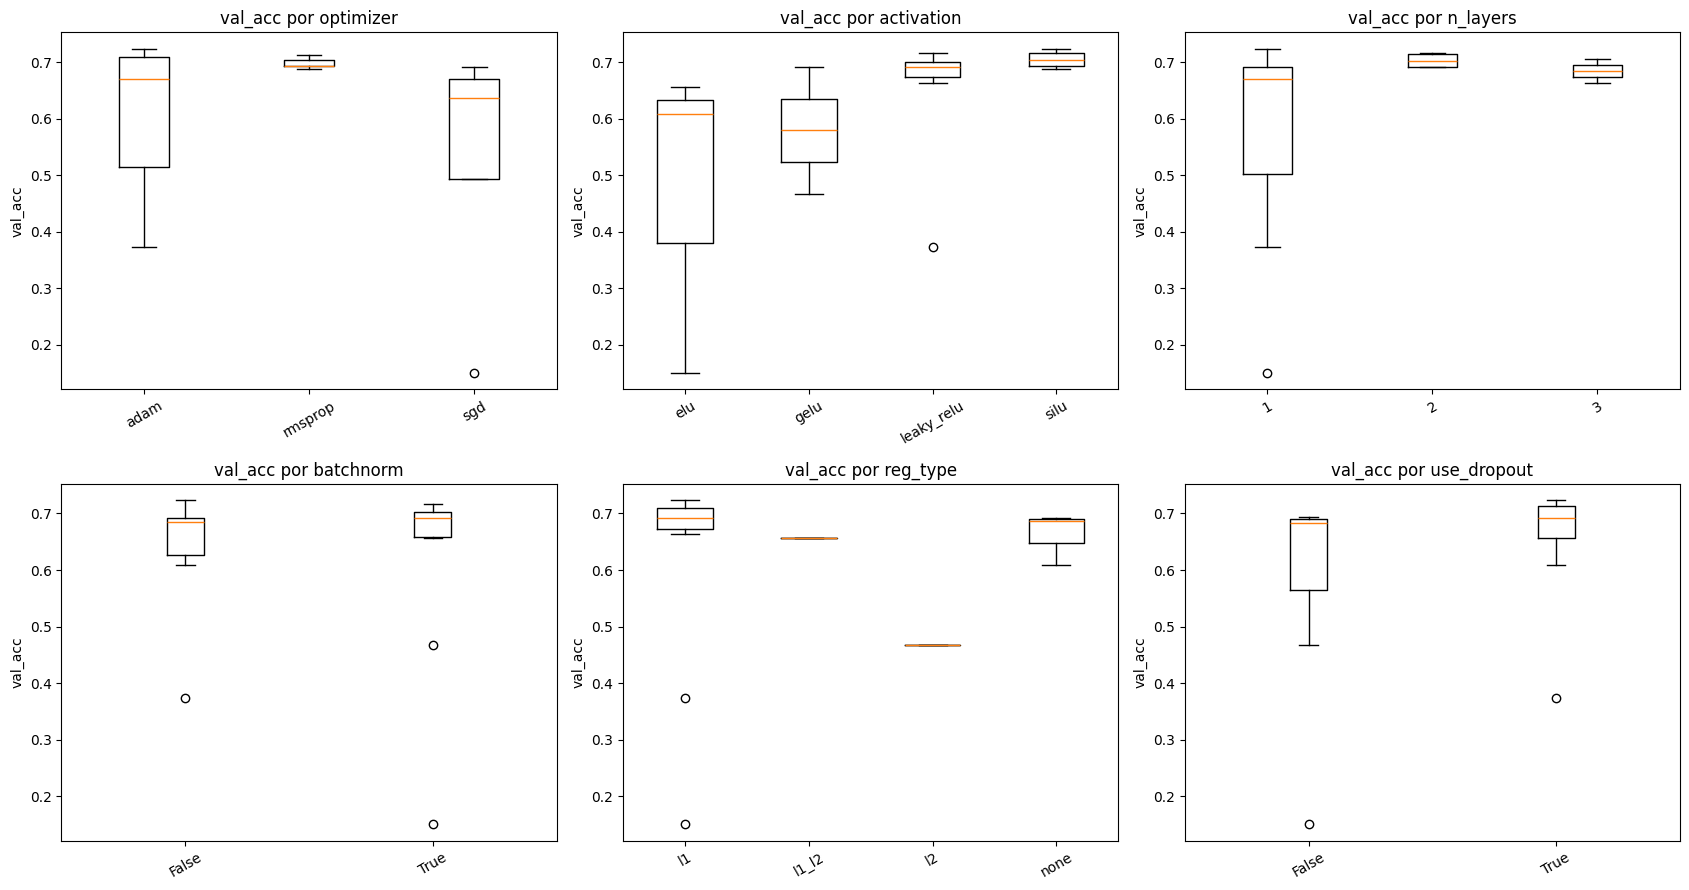

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, by in zip(axes.flat, ["optimizer", "activation", "n_layers", "batchnorm", "reg_type", "use_dropout"]):
    groups = sorted(done[by].unique(), key=str)
    ax.boxplot([done[done[by] == g]["value"] for g in groups])
    ax.set_xticklabels([str(g) for g in groups], rotation=30)
    ax.set_title(f"val_acc por {by}"); ax.set_ylabel("val_acc")
plt.tight_layout(); plt.show()


### 6.3 Performance vs tiempo de entrenamiento y tamaño del modelo

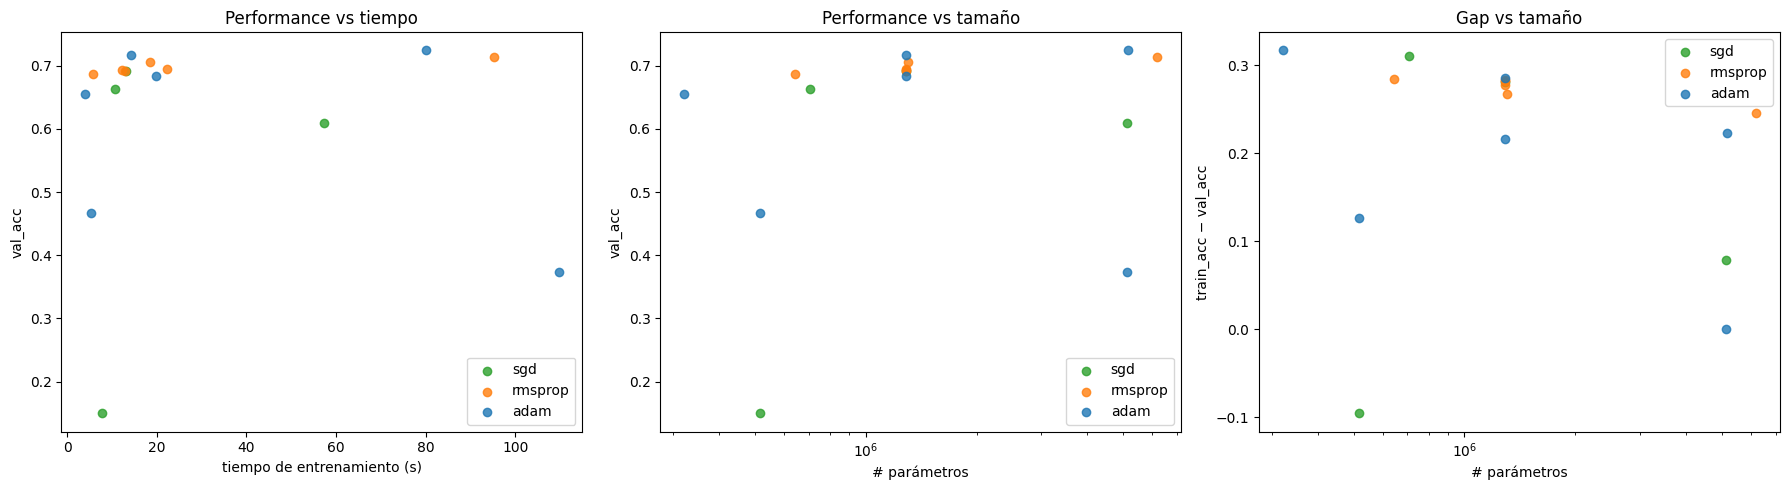

Trials en la frontera de Pareto (tiempo vs val_acc):


,number,value,train_time,optimizer,activation,arch,n_params
7,7,0.6929,12.1643,rmsprop,leaky_relu,256,1285652
8,8,0.6558,3.9847,adam,elu,64,321428
13,13,0.6871,5.6525,rmsprop,silu,128,642708
14,14,0.7163,14.2050,adam,leaky_relu,128-32,1285076
23,23,0.7238,79.9959,adam,silu,1024,5141524


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {"sgd": "tab:green", "rmsprop": "tab:orange", "adam": "tab:blue"}
for o, c in colors.items():
    d = done[done.optimizer == o]
    axes[0].scatter(d.train_time, d.value, c=c, label=o, alpha=.8)
    axes[1].scatter(d.n_params, d.value, c=c, label=o, alpha=.8)
    axes[2].scatter(d.n_params, d.gap, c=c, label=o, alpha=.8)
axes[0].set_xlabel("tiempo de entrenamiento (s)"); axes[0].set_ylabel("val_acc"); axes[0].set_title("Performance vs tiempo")
axes[1].set_xscale("log"); axes[1].set_xlabel("# parámetros"); axes[1].set_ylabel("val_acc"); axes[1].set_title("Performance vs tamaño")
axes[2].set_xscale("log"); axes[2].set_xlabel("# parámetros"); axes[2].set_ylabel("train_acc − val_acc"); axes[2].set_title("Gap vs tamaño")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

# Frontera de Pareto (val_acc alta, tiempo bajo)
d = done.sort_values("train_time")
pareto, best_so_far = [], -1
for _, r in d.iterrows():
    if r["value"] > best_so_far:
        pareto.append(r["number"]); best_so_far = r["value"]
print("Trials en la frontera de Pareto (tiempo vs val_acc):")
display(done[done.number.isin(pareto)][["number", "value", "train_time", "optimizer", "activation", "arch", "n_params"]].round(4))

### 6.4 Curvas de aprendizaje y importancia de hiperparámetros

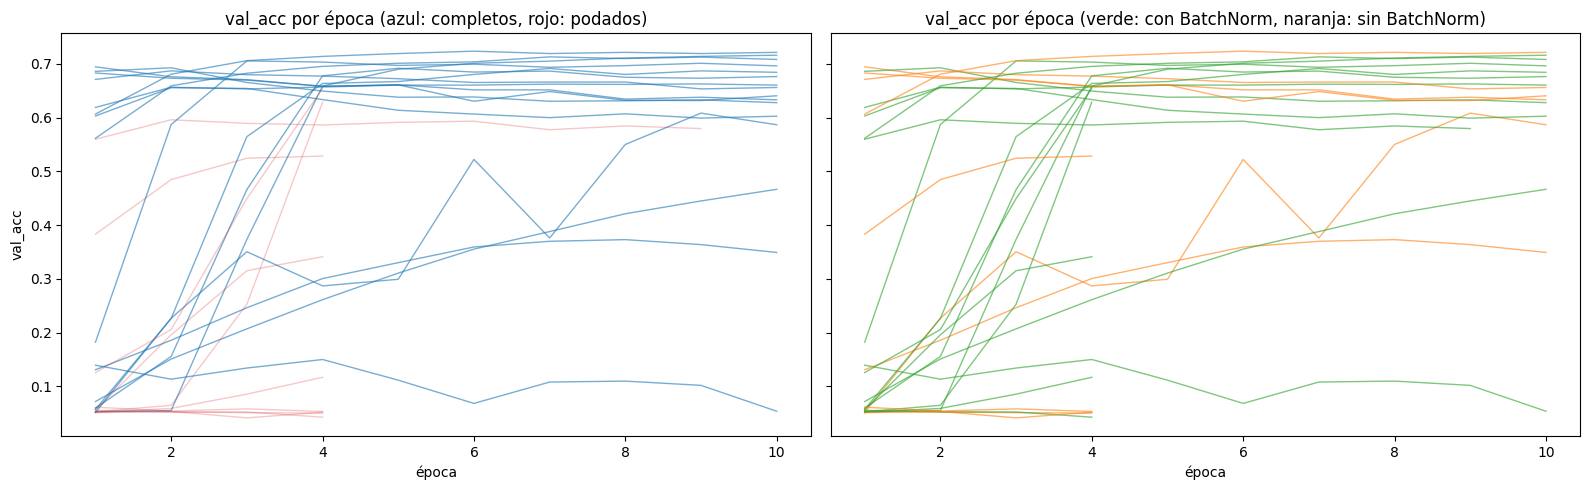

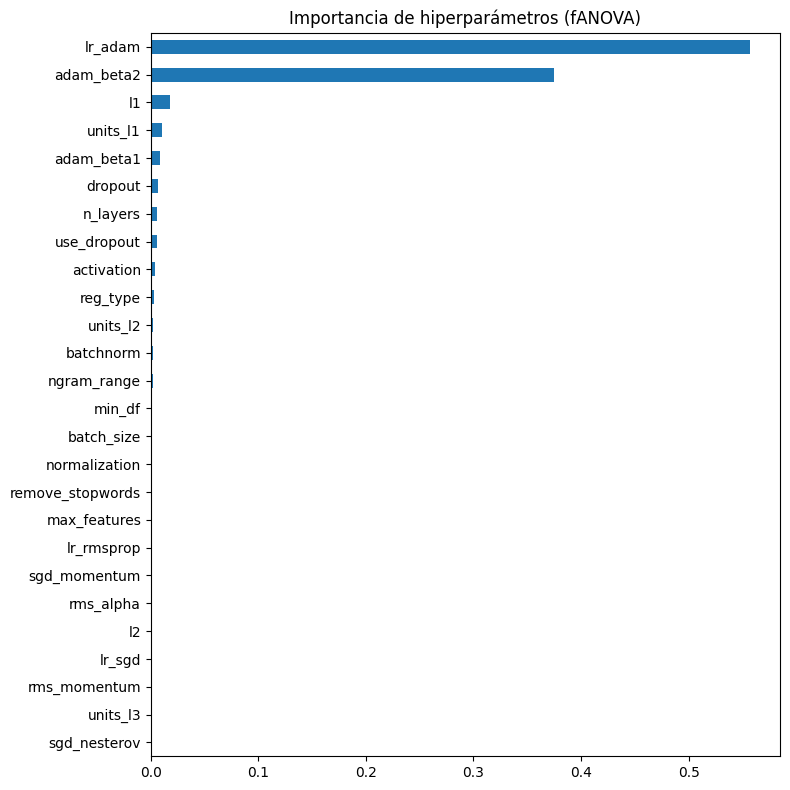

In [ ]:
# Curvas val_acc por época de todos los trials (los podados terminan antes)
bn_by_trial = {t.number: bool(t.params.get("batchnorm", False)) for t in study.trials}
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for t in study.trials:
    if not t.intermediate_values: continue
    ep, v = zip(*sorted(t.intermediate_values.items()))
    pruned = t.state == optuna.trial.TrialState.PRUNED
    axes[0].plot(np.array(ep) + 1, v, color="tab:red" if pruned else "tab:blue", alpha=.25 if pruned else .6, lw=1)
    axes[1].plot(np.array(ep) + 1, v, color="tab:green" if bn_by_trial[t.number] else "tab:orange", alpha=.6, lw=1)
axes[0].set_title("val_acc por época (azul: completos, rojo: podados)")
axes[1].set_title("val_acc por época (verde: con BatchNorm, naranja: sin BatchNorm)")
for a in axes: a.set_xlabel("época")
axes[0].set_ylabel("val_acc")
plt.tight_layout(); plt.show()

try:
    imp = optuna.importance.get_param_importances(study)
    s = pd.Series(imp).sort_values()
    s.plot.barh(figsize=(8, 8), title="Importancia de hiperparámetros (fANOVA)")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("No se pudo calcular importancia:", e)


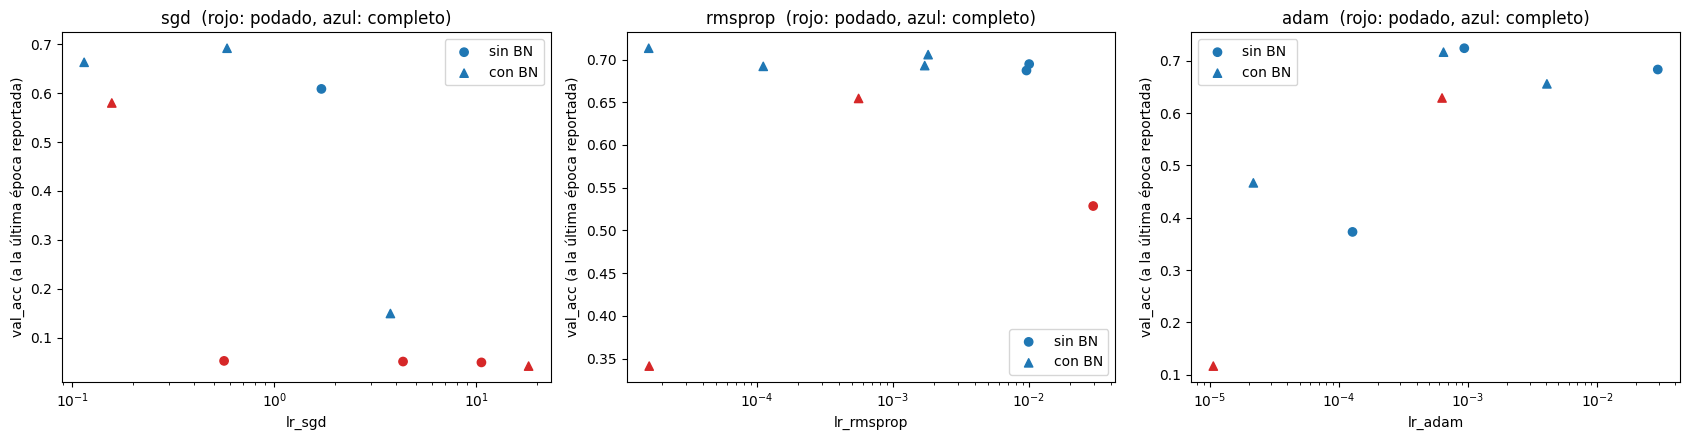

In [ ]:
# Relación entre lr y val_acc, por optimizador (triángulo: con BatchNorm, círculo: sin BatchNorm)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (o, col) in zip(axes, [("sgd", "lr_sgd"), ("rmsprop", "lr_rmsprop"), ("adam", "lr_adam")]):
    if col not in df: ax.set_title(f"{o}: sin trials"); continue
    for bn, mk in [(False, "o"), (True, "^")]:
        d = df[(df.optimizer == o) & (df.batchnorm == bn)]
        ax.scatter(d[col], d["value"], marker=mk, c=np.where(d.state == "PRUNED", "tab:red", "tab:blue"),
                   label="con BN" if bn else "sin BN")
    ax.set_xscale("log"); ax.set_xlabel(col); ax.set_ylabel("val_acc (a la última época reportada)")
    ax.set_title(o + "  (rojo: podado, azul: completo)"); ax.legend()
plt.tight_layout(); plt.show()


### 6.5 Regularización dentro de la búsqueda de Optuna

Acá se ven los mismos efectos de la sección 5, pero **mezclados con el resto de los hiperparámetros** (por eso son más ruidosos y hay que leerlos como tendencias, no como causas aisladas): tamaño de los pesos vs gap según el tipo de regularización, ruido de las curvas y tiempo por época con/sin BatchNorm y con/sin dropout.

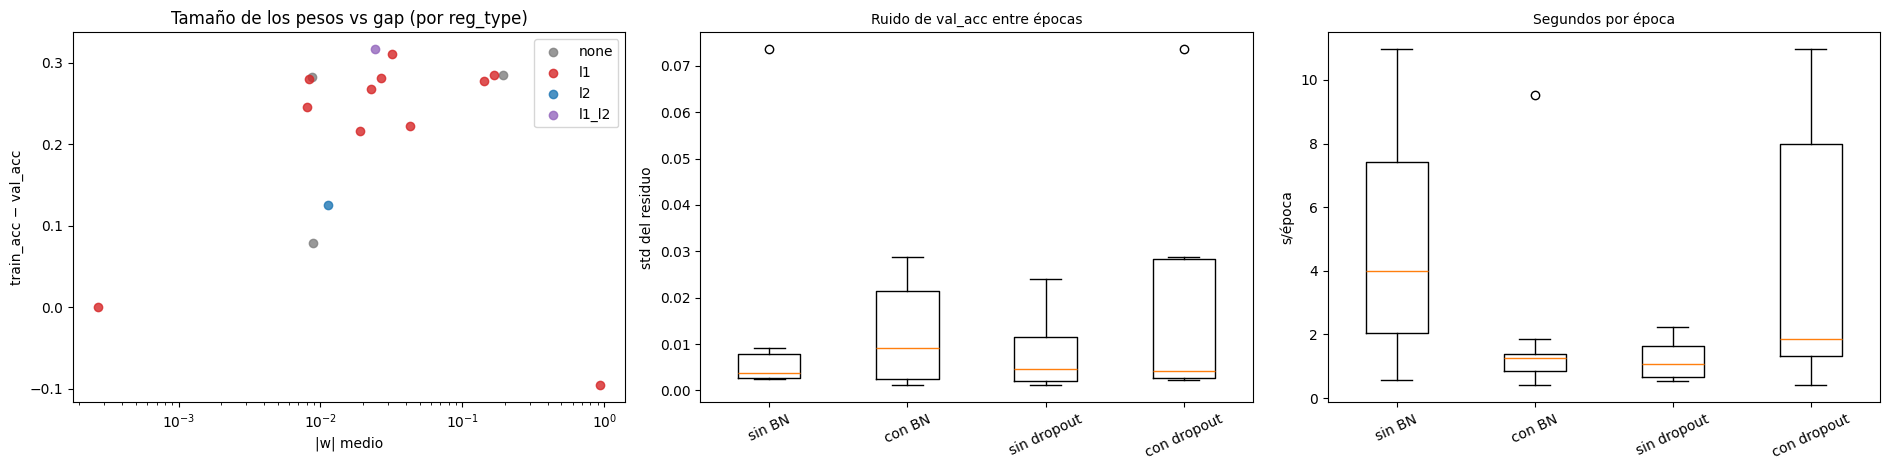

In [ ]:
def box(ax, groups, title, ylabel):
    ax.boxplot([g.dropna().values if len(g.dropna()) else [np.nan] for _, g in groups])
    ax.set_xticklabels([n for n, _ in groups], rotation=25); ax.set_title(title, fontsize=10); ax.set_ylabel(ylabel)

done["s_per_epoch"] = done["train_time"] / done["epochs_run"]
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
palette = {"none": "tab:gray", "l1": "tab:red", "l2": "tab:blue", "l1_l2": "tab:purple"}
for r, c in palette.items():
    d = done[done.reg_type == r]
    axes[0].scatter(d.mean_abs_w, d.gap, c=c, label=r, alpha=.8)
axes[0].set_xscale("log"); axes[0].set_xlabel("|w| medio"); axes[0].set_ylabel("train_acc − val_acc")
axes[0].set_title("Tamaño de los pesos vs gap (por reg_type)"); axes[0].legend()
groups = [("sin BN", done[~done.batchnorm]), ("con BN", done[done.batchnorm]),
          ("sin dropout", done[~done.use_dropout]), ("con dropout", done[done.use_dropout])]
box(axes[1], [(n, g["val_acc_noise"]) for n, g in groups], "Ruido de val_acc entre épocas", "std del residuo")
box(axes[2], [(n, g["s_per_epoch"]) for n, g in groups], "Segundos por época", "s/época")
plt.tight_layout(); plt.show()

### 6.6 Conclusiones: números de esta corrida

La celda siguiente calcula las conclusiones con los resultados de esta ejecución (así las cifras nunca quedan desactualizadas). La interpretación escrita está en 6.7.

In [ ]:
pd.set_option("display.width", 200)
noise_ref = SEED_STD if "SEED_STD" in globals() else None
def _vs_noise(diff):
    if noise_ref is None: return ""
    return " (mayor que el desvío entre semillas: probablemente real)" if abs(diff) > noise_ref else " (menor que el desvío entre semillas: no concluyente)"

print("=" * 78); print("CONCLUSIONES CALCULADAS CON ESTA CORRIDA"); print("=" * 78)

# 1) Optimizadores
tab = pd.DataFrame({
    "trials": df.groupby("optimizer").size(),
    "completos": done.groupby("optimizer").size(),
    "podados": df[df.state == "PRUNED"].groupby("optimizer").size(),
    "val_acc_max": done.groupby("optimizer")["value"].max(),
    "val_acc_media": done.groupby("optimizer")["value"].mean(),
    "tiempo_medio_s": done.groupby("optimizer")["train_time"].mean()}).fillna(0).round(3)
print("\n1) OPTIMIZADORES (búsqueda balanceada)"); display(tab)
ok = tab[tab.completos > 0]
if len(ok):
    bo, bm = ok["val_acc_max"].idxmax(), ok["val_acc_media"].idxmax()
    print(f"   → Mejor val_acc máxima: {bo} ({ok.loc[bo,'val_acc_max']:.3f}). Mejor media entre trials completos: {bm} ({ok.loc[bm,'val_acc_media']:.3f}).")
    if (tab.completos == 0).any():
        print("   → Optimizadores sin ningún trial completo:", list(tab.index[tab.completos == 0]), "(todos fueron podados: necesitan más épocas o mejor lr).")
if "summ" in globals():
    b = summ["val_acc_final_media"].idxmax(); s2 = summ["val_acc_final_media"].sort_values(ascending=False)
    d = s2.iloc[0] - s2.iloc[1]
    print(f"   → Experimento controlado (5.8, 3 semillas): mejor '{b}' con {s2.iloc[0]:.3f}; ventaja sobre el segundo = {d:.3f}{_vs_noise(d)}.")
    try:
        m0, m9 = summ.loc["SGD (momentum 0)", "val_acc_final_media"], summ.loc["SGD (momentum 0.9)", "val_acc_final_media"]
        a9, a5 = summ.loc["Adam (b1 0.9, b2 0.999)", "val_acc_final_media"], summ.loc["Adam (b1 0.5, b2 0.999)", "val_acc_final_media"]
        print(f"   → Momento de 1er orden: SGD m=0 → m=0.9: {m0:.3f} → {m9:.3f}{_vs_noise(m9-m0)}; Adam β1 0.9 → 0.5: {a9:.3f} → {a5:.3f}{_vs_noise(a5-a9)}.")
    except KeyError: pass

# 2) Activaciones
g = done.groupby("activation")["value"].agg(["count", "mean", "max"]).round(4)
print("\n2) ACTIVACIONES"); display(g.sort_values("mean", ascending=False))
if len(g) > 1:
    d = g["mean"].max() - g["mean"].min()
    print(f"   → Mejor media: {g['mean'].idxmax()}; peor: {g['mean'].idxmin()}; diferencia entre ambas = {d:.3f}{_vs_noise(d)}.")

# 3) Profundidad
g = done.groupby("n_layers").agg(trials=("value", "size"), val_acc_media=("value", "mean"), val_acc_max=("value", "max"),
                                 gap_medio=("gap", "mean"), tiempo_medio_s=("train_time", "mean"), params_medios=("n_params", "mean")).round(4)
print("\n3) PROFUNDIDAD"); display(g)
if len(g) > 1:
    print(f"   → Mejor profundidad por media: {g['val_acc_media'].idxmax()} capa(s); mayor gap medio (sobreajuste): {g['gap_medio'].idxmax()} capa(s).")

# 4) Tiempos
rho = done[["n_params", "train_time"]].corr(method="spearman").iloc[0, 1]
near = done[done.value >= done.value.max() - 0.01].sort_values("train_time").iloc[0]
print(f"\n4) TIEMPOS: mediana de entrenamiento por trial = {done.train_time.median():.1f}s; correlación (Spearman) # parámetros vs tiempo = {rho:.2f}.")
print(f"   → El trial más rápido a menos de 1 punto del mejor: #{int(near.number)} ({near.optimizer}, {near.arch}, BN={near.batchnorm}) con val_acc {near.value:.3f} en {near.train_time:.1f}s "
      f"(el mejor tardó {done.loc[done.value.idxmax(), 'train_time']:.1f}s).")

# 5) Pruning
ep_used, ep_max = df["epochs_run"].fillna(0).sum(), len(df) * MAX_EPOCHS_SEARCH
print(f"\n5) PRUNING: {(df.state=='PRUNED').sum()} de {len(df)} trials podados ({100*(df.state=='PRUNED').mean():.0f}%); "
      f"se ejecutaron {int(ep_used)} de {ep_max} épocas posibles ({100*ep_used/ep_max:.0f}%), es decir {100*(1-ep_used/ep_max):.0f}% de ahorro.")

# 6) Sobreajuste y regularización controlada
if "df_reg" in globals():
    r = df_reg.set_index("variant"); base_r = r.loc["baseline"]
    best_v = r["val_loss_min"].drop("baseline").idxmin()
    print(f"\n6) SOBREAJUSTE: la red base ({REG_LAYERS}x{REG_UNITS}) tiene val_loss {base_r.val_loss_min:.3f} (época {int(base_r.epoch_min_val_loss)}) → {base_r.val_loss_final:.3f} al final; gap {base_r.gap:.3f}.")
    print(f"   → Variante con menor val_loss mínima: '{best_v}' ({r.loc[best_v,'val_loss_min']:.3f}); su subida de val_loss es {r.loc[best_v,'val_loss_rise']:.3f} (baseline {base_r.val_loss_rise:.3f}).")
    best_acc = r["best_val_acc"].idxmax()
    d = r.loc[best_acc, "best_val_acc"] - base_r.best_val_acc
    print(f"   → Mejor val_acc: '{best_acc}' ({r.loc[best_acc,'best_val_acc']:.3f}); mejora sobre el baseline = {d:.3f}{_vs_noise(d)}.")

# 7) Regularización dentro de la búsqueda
print("\n7) REGULARIZACIÓN EN LA BÚSQUEDA")
for by in ["batchnorm", "reg_type", "use_dropout"]:
    gg = done.groupby(by)["value"].agg(["count", "mean", "max"]).round(4)
    print(f"   por {by}:"); display(gg)

CONCLUSIONES CALCULADAS CON ESTA CORRIDA

1) OPTIMIZADORES (búsqueda balanceada)


,trials,completos,podados,val_acc_max,val_acc_media,tiempo_medio_s
optimizer,,,,,,
adam,8,6,2,0.724,0.603,38.842
rmsprop,9,6,3,0.713,0.698,27.819
sgd,9,4,5,0.692,0.528,22.289


   → Mejor val_acc máxima: adam (0.724). Mejor media entre trials completos: rmsprop (0.698).
   → Experimento controlado (5.8, 3 semillas): mejor 'Adam (b1 0.5, b2 0.999)' con 0.744; ventaja sobre el segundo = 0.001 (menor que el desvío entre semillas: no concluyente).
   → Momento de 1er orden: SGD m=0 → m=0.9: 0.372 → 0.472 (mayor que el desvío entre semillas: probablemente real); Adam β1 0.9 → 0.5: 0.743 → 0.744 (menor que el desvío entre semillas: no concluyente).

2) ACTIVACIONES


,count,mean,max
activation,,,
silu,4,0.7047,0.7238
leaky_relu,7,0.6466,0.7163
gelu,2,0.5791,0.6916
elu,3,0.4714,0.6558


   → Mejor media: silu; peor: elu; diferencia entre ambas = 0.233 (mayor que el desvío entre semillas: probablemente real).

3) PROFUNDIDAD


,trials,val_acc_media,val_acc_max,gap_medio,tiempo_medio_s,params_medios
n_layers,,,,,,
1,10,0.5735,0.7238,0.1777,32.4305,2125895.2
2,4,0.7033,0.7163,0.2564,33.9233,2513300.0
3,2,0.6843,0.7057,0.2892,14.5591,1007316.0


... (2 outputs left out)

   por reg_type:


,count,mean,max
reg_type,,,
l1,11,0.6188,0.7238
l1_l2,1,0.6558,0.6558
l2,1,0.4666,0.4666
none,3,0.6625,0.6920


   por use_dropout:


,count,mean,max
use_dropout,,,
False,7,0.5766,0.6947
True,9,0.6534,0.7238


### 6.7 Análisis y conclusiones

Los resultados del trabajo se interpretan a partir de las características de la representación utilizada. Dado que las entradas son vectores TF-IDF ralos, en los que cada término aparece en pocos documentos, SGD actualiza cada peso proporcionalmente a su gradiente, que resulta muy pequeño para los términos poco frecuentes, por lo que requiere tasas de aprendizaje elevadas y un mayor número de épocas. RMSprop y Adam, en cambio, normalizan el paso mediante el segundo momento y asignan una tasa de aprendizaje efectiva a cada parámetro, lo que resulta ventajoso en este tipo de entrada y permite esperar una convergencia más temprana. Como la búsqueda anterior concentró 36 de 40 ensayos en RMSprop y podó a SGD con una mediana global, no admitía comparaciones. En esta versión la búsqueda está balanceada, el pruning compara cada ensayo con los de su mismo optimizador y el efecto de los momentos se evalúa con tres semillas, considerando relevantes únicamente las diferencias que superan el desvío entre réplicas. Respecto de las funciones de activación, se espera un desempeño similar entre ReLU, LeakyReLU, ELU, GELU y SiLU, y un rendimiento menor para tanh debido a su saturación; si la diferencia entre la mejor y la peor es inferior al desvío entre semillas, la activación no resulta determinante. En cuanto a la profundidad, la primera capa concentra casi toda la capacidad (max_features × neuronas pesos) y la representación TF-IDF es aproximadamente linealmente separable para clasificación temática, por lo que añadir capas aporta poco y aumenta el riesgo de sobreajuste, de modo que 1 o 2 capas deberían igualar o superar a 3. El tiempo de cómputo está dominado por esa misma capa y crece con max_features y el ancho inicial, con una correlación alta entre cantidad de parámetros y duración. Si bien BatchNorm y L1 encarecen cada época, BatchNorm puede compensarlo al admitir tasas más altas y menos épocas, y la frontera de Pareto permite identificar modelos considerablemente más baratos a menos de un punto del mejor. El pruning reduce de forma sustancial el número de épocas ejecutadas, a costa del riesgo de descartar configuraciones de arranque lento (SGD, dropout, L1), que se mitiga con tres épocas de calentamiento, diez épocas por ensayo y la comparación intra-optimizador; en todos los casos la configuración final se reentrena completa.

Finalmente, según el criterio de la sección 4.1, la red elegida presenta una train_acc alta y una val_loss que alcanza su mínimo en una época temprana y luego aumenta, patrón característico de sobreajuste. Las técnicas de la sección 5 lo abordan por mecanismos distintos: L2 contrae el conjunto de pesos, L1 anula entradas, el dropout promedia subredes y BatchNorm estabiliza la optimización y permite tasas de aprendizaje mayores. El trabajo presenta limitaciones que deben tenerse presentes. Cada variante de la sección 5 se ejecutó una sola vez, por lo que diferencias de val_acc menores al desvío entre semillas no deben interpretarse como mejoras. El val_acc utilizado por Optuna es el máximo sobre épocas y por tanto resulta algo optimista, razón por la cual el entrenamiento final reporta el valor de la última época. La búsqueda cuenta con una única corrida por configuración y su solidez estadística proviene de los experimentos con réplicas (secciones 5.8 y 7.1). El espacio de búsqueda y el presupuesto están acotados por restricciones de cómputo, y los valores de λ para L1 y L2 conforman una grilla gruesa.

## 7. Entrenamiento final y evaluación en test

Con los mejores HPs se reentrena con **todo** el train set, durante `best_epoch` épocas (la época donde se alcanzó la mejor val_acc en la búsqueda; así no se usa el test para decidir cuándo cortar) y recién ahí se evalúa en test.




In [ ]:
best_trial = study.best_trial
bp = best_trial.params
hidden = [bp[f"units_l{i+1}"] for i in range(bp["n_layers"])]
opt_name = best_trial.user_attrs["optimizer"]
lr = bp[f"lr_{opt_name}"]
opt_kw = {"sgd": dict(momentum=bp.get("sgd_momentum"), nesterov=bp.get("sgd_nesterov")),
          "rmsprop": dict(alpha=bp.get("rms_alpha"), momentum=bp.get("rms_momentum")),
          "adam": dict(beta1=bp.get("adam_beta1"), beta2=bp.get("adam_beta2"))}[opt_name]
dropout_f, bn_f = bp.get("dropout", 0.0), bp["batchnorm"]
l1_f, l2_f = bp.get("l1", 0.0), bp.get("l2", 0.0)
EPOCHS_FINAL = int(best_trial.user_attrs["best_epoch"])
print("Arquitectura:", hidden, "| activación:", bp["activation"], "| BatchNorm:", bn_f, "| dropout:", round(dropout_f, 3))
print("Regularización:", bp["reg_type"], "| l1:", l1_f, "| l2:", l2_f)
print("Optimizador:", opt_name, "| lr:", lr, "|", opt_kw)
print("Épocas finales:", EPOCHS_FINAL)

ngram_t = (1, 1) if bp["ngram_range"] == "1gram" else (1, 2)
train_texts, test_texts = preprocessed_cache[(bp["remove_stopwords"], bp["normalization"])]
X_train_f, X_test_f, vectorizer_final = vectorize_data(train_texts, test_texts, ngram_t, bp["max_features"], bp["min_df"])
Xtr_f, Xte_f = to_dense(X_train_f), to_dense(X_test_f)
ytr_f = torch.tensor(y_all_train, dtype=torch.long, device=device)
yte_f = torch.tensor(y_test, dtype=torch.long, device=device)

set_seed()
model = MLP(Xtr_f.shape[1], hidden, NUM_CLASSES, bp["activation"], dropout_f, bn_f)
optimizer = build_optimizer(param_groups(model, l2_f), opt_name, lr, **opt_kw)
hist_f, t_f = train_model(model, optimizer, Xtr_f, ytr_f, Xte_f, yte_f, EPOCHS_FINAL, bp["batch_size"],
                          verbose=True, tag="final", l1=l1_f)
print(f"\nTiempo de entrenamiento final: {t_f:.1f}s | parámetros: {count_params(model):,}")
print("Pesos del modelo final:", {k: round(v, 5) for k, v in weight_stats(model).items()})


Arquitectura: [1024] | activación: silu | BatchNorm: False | dropout: 0.535
Regularización: l1 | l1: 1.1346405425639214e-08 | l2: 0.0
Optimizador: adam | lr: 0.0009357478346787644 | {'beta1': 0.8755512471370264, 'beta2': 0.9453333248970166}
Épocas finales: 6
[final] ep 01/6 train_loss 1.9997 acc 0.6763 | val_loss 2.1323 acc 0.5888 | 9.69s
[final] ep 02/6 train_loss 1.1394 acc 0.7685 | val_loss 1.4082 acc 0.6510 | 17.20s
[final] ep 03/6 train_loss 0.8032 acc 0.8089 | val_loss 1.1937 acc 0.6593 | 9.10s
[final] ep 04/6 train_loss 0.6283 acc 0.8419 | val_loss 1.1308 acc 0.6661 | 8.83s
[final] ep 05/6 train_loss 0.5125 acc 0.8699 | val_loss 1.1161 acc 0.6697 | 8.66s
[final] ep 06/6 train_loss 0.4256 acc 0.8921 | val_loss 1.1265 acc 0.6681 | 8.59s

Tiempo de entrenamiento final: 62.1s | parámetros: 5,141,524
Pesos del modelo final: {'mean_abs_w': 0.0374, 'max_abs_w': 0.35888, 'frac_small_w': 0.03091, 'w_norm': 109.72856, 'dead_inputs': 0.001}


Accuracy en test: 0.6681

                          precision    recall  f1-score   support

             alt.atheism       0.47      0.51      0.49       319
           comp.graphics       0.60      0.62      0.61       389
 comp.os.ms-windows.misc       0.62      0.60      0.61       394
comp.sys.ibm.pc.hardware       0.67      0.61      0.64       392
   comp.sys.mac.hardware       0.71      0.65      0.68       385
          comp.windows.x       0.76      0.67      0.71       395
            misc.forsale       0.74      0.79      0.77       390
               rec.autos       0.72      0.66      0.69       396
         rec.motorcycles       0.46      0.77      0.58       398
      rec.sport.baseball       0.88      0.79      0.83       397
        rec.sport.hockey       0.90      0.87      0.89       399
               sci.crypt       0.79      0.72      0.75       396
         sci.electronics       0.56      0.57      0.56       393
                 sci.med       0.77      0.75    

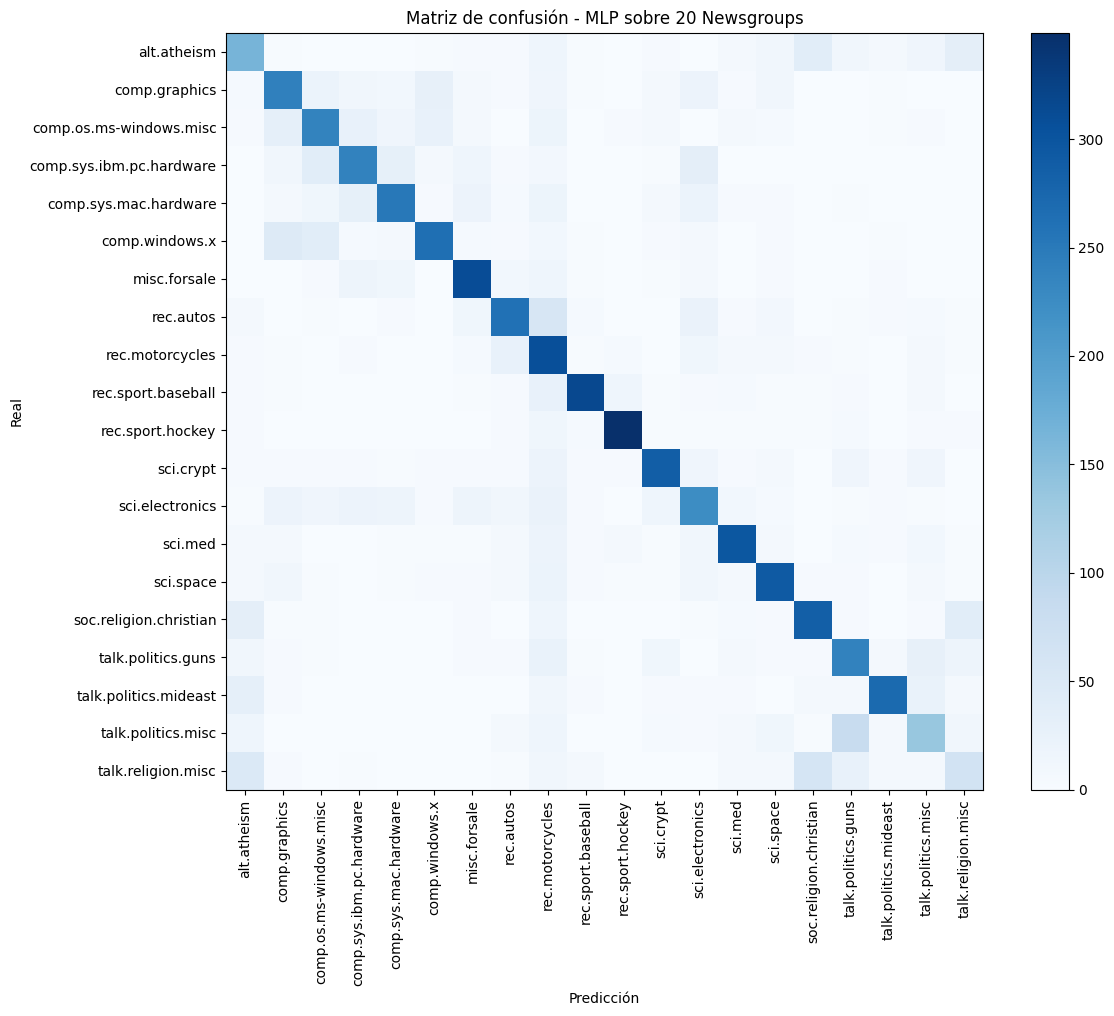

In [ ]:
model.eval()
with torch.no_grad():
    preds = torch.cat([model(Xte_f[i:i+2048]).argmax(1) for i in range(0, Xte_f.size(0), 2048)]).cpu().numpy()
print(f"Accuracy en test: {accuracy_score(y_test, preds):.4f}\n")
print(classification_report(y_test, preds, target_names=class_names))

cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión - MLP sobre 20 Newsgroups")
plt.tight_layout(); plt.show()

### 7.1 Comparación con el modelo del TP1 (Softmax) y con baselines

Para saber si el MLP realmente aporta, lo comparamos en el **mismo test** con:
- **Baseline trivial**: predecir siempre la clase más frecuente del train.
- **Softmax (regresión logística multinomial)**: el modelo del TP1, es decir, una única capa lineal sobre el mismo TF-IDF (misma vectorización que el mejor MLP). Su learning rate y su número de épocas se eligen con la *validación* (lr ∈ {1e-3, 1e-2}), igual que se hizo con el MLP, para que la comparación sea justa.
- **MLP final**: la mejor configuración de Optuna.

Ambos modelos se entrenan con 3 semillas sobre todo el train y se reporta la accuracy de test de la **última época** (media ± desvío).

In [ ]:
FINAL_SEEDS = [0, 1, 2]

# 1) Baseline trivial
maj = int(np.bincount(y_all_train).argmax())
acc_major = float((y_test == maj).mean())

# 2) Softmax: elegimos lr y número de épocas con la VALIDACIÓN (mismo split que la búsqueda)
Xa, Xb = get_vectorized(bp["remove_stopwords"], bp["normalization"], bp["ngram_range"], bp["max_features"], bp["min_df"])
Xa, Xb = to_dense(Xa), to_dense(Xb)
ya, yb = torch.tensor(y_tr, dtype=torch.long, device=device), torch.tensor(y_val, dtype=torch.long, device=device)
sm_val = {}
for lr_s in [1e-3, 1e-2]:
    set_seed()
    m_s = MLP(Xa.shape[1], [], NUM_CLASSES)          # sin capas ocultas = Softmax
    h_s, _ = train_model(m_s, build_optimizer(m_s.parameters(), "adam", lr_s), Xa, ya, Xb, yb, 15, 256,
                         tag=f"softmax lr={lr_s:g}", eval_train=False)
    sm_val[lr_s] = (max(h_s["val_acc"]), int(np.argmax(h_s["val_acc"])) + 1)
lr_sm = max(sm_val, key=lambda k: sm_val[k][0]); ep_sm = sm_val[lr_sm][1]
print(f"Softmax: lr elegido {lr_sm:g}, épocas {ep_sm} (val_acc {sm_val[lr_sm][0]:.4f})")
del Xa, Xb

# 3) Réplicas sobre todo el train y evaluación en test (última época)
rows = []
for sd in FINAL_SEEDS:
    for nombre in ["Softmax (TP1)", "MLP (mejor de Optuna)"]:
        set_seed(sd)
        if nombre.startswith("Softmax"):
            mm = MLP(Xtr_f.shape[1], [], NUM_CLASSES); oo = build_optimizer(mm.parameters(), "adam", lr_sm)
            hh, tt = train_model(mm, oo, Xtr_f, ytr_f, Xte_f, yte_f, ep_sm, 256, eval_train=False)
        else:
            mm = MLP(Xtr_f.shape[1], hidden, NUM_CLASSES, bp["activation"], dropout_f, bn_f)
            oo = build_optimizer(param_groups(mm, l2_f), opt_name, lr, **opt_kw)
            hh, tt = train_model(mm, oo, Xtr_f, ytr_f, Xte_f, yte_f, EPOCHS_FINAL, bp["batch_size"], eval_train=False, l1=l1_f)
        rows.append(dict(modelo=nombre, seed=sd, test_acc=hh["val_acc"][-1], params=count_params(mm), time_s=tt))
df_cmp = pd.DataFrame(rows)
res = df_cmp.groupby("modelo", sort=False).agg(test_acc_media=("test_acc", "mean"), test_acc_std=("test_acc", "std"),
                                              params=("params", "first"), tiempo_s=("time_s", "mean")).round(4)
res.loc["Baseline trivial (clase mayoritaria)"] = [acc_major, 0.0, 0, 0.0]
display(res)

a = df_cmp[df_cmp.modelo.str.startswith("MLP")].test_acc; b = df_cmp[df_cmp.modelo.str.startswith("Softmax")].test_acc
d = a.mean() - b.mean()
print(f"\nMLP − Softmax = {d:+.4f} en accuracy de test (desvío entre semillas: MLP {a.std():.4f}, Softmax {b.std():.4f}).")
print("→ La mejora del MLP es", "mayor que el ruido entre semillas." if abs(d) > max(a.std(), b.std()) * 2 else
      "comparable al ruido entre semillas: no se puede afirmar que el MLP supere al Softmax en este problema.")
print(f"→ El MLP usa {res.loc['MLP (mejor de Optuna)','params']/max(res.loc['Softmax (TP1)','params'],1):.1f}x los parámetros y {res.loc['MLP (mejor de Optuna)','tiempo_s']/max(res.loc['Softmax (TP1)','tiempo_s'],1e-9):.1f}x el tiempo de entrenamiento del Softmax.")

Softmax: lr elegido 0.01, épocas 8 (val_acc 0.7123)


,test_acc_media,test_acc_std,params,tiempo_s
modelo,,,,
Softmax (TP1),0.645600,0.0013,100020.0,2.2805
MLP (mejor de Optuna),0.669500,0.0016,5141524.0,55.5397
Baseline trivial (clase mayoritaria),0.052974,0.0000,0.0,0.0000



MLP − Softmax = +0.0239 en accuracy de test (desvío entre semillas: MLP 0.0016, Softmax 0.0013).
→ La mejora del MLP es mayor que el ruido entre semillas.
→ El MLP usa 51.4x los parámetros y 24.4x el tiempo de entrenamiento del Softmax.


¿Por qué el MLP supera (o no) al Softmax en este problema?

Una representación TF-IDF de bolsa de palabras es aproximadamente linealmente separable para la clasificación temática, dado que cada grupo de noticias posee un vocabulario característico al que un modelo lineal como Softmax puede asignar pesos positivos. Por ello, un modelo lineal bien entrenado constituye un baseline muy competitivo en 20 Newsgroups, y cabe esperar que el MLP aporte una mejora modesta. Su ventaja potencial radica en capturar interacciones entre términos y n-gramas que un modelo lineal no puede representar, pero ello implica un costo: una cantidad considerablemente mayor de parámetros (la primera capa contiene max_features × neuronas pesos), un entrenamiento más lento y una mayor propensión al sobreajuste en ausencia de regularización, como se observó en las secciones 4 y 5. Para interpretar la tabla comparativa, el baseline trivial (clase mayoritaria) establece el piso de desempeño, por encima del cual debe situarse cualquier modelo útil. Si la diferencia entre MLP y Softmax supera el desvío entre semillas, la mejora puede considerarse real. Si es comparable a dicho desvío, la conclusión pertinente es que el MLP no justifica su costo adicional en este problema. Ambos desenlaces son válidos, siempre que estén respaldados por la variabilidad entre réplicas y por una comparación sobre el mismo conjunto de test con idéntico preprocesamiento.